**Table of contents**<a id='toc0_'></a>    
- [Imports](#toc1_)    
- [Read Datasets](#toc2_)    
- [Experiments](#toc3_)    
  - [m = 1.3](#toc3_1_)    
    - [Dataset 0](#toc3_1_1_)    
    - [Dataset 1](#toc3_1_2_)    
    - [Dataset 2](#toc3_1_3_)    
  - [m = 1.4](#toc3_2_)    
    - [Dataset 0](#toc3_2_1_)    
    - [Dataset 1](#toc3_2_2_)    
    - [Dataset 2](#toc3_2_3_)
  - [m = 1.5](#toc3_3_)    
    - [Dataset 0](#toc3_3_1_)    
    - [Dataset 1](#toc3_3_2_)    
    - [Dataset 2](#toc3_3_3_)    
  - [m = 1.6](#toc3_4_)    
    - [Dataset 0](#toc3_4_1_)    
    - [Dataset 1](#toc3_4_2_)    
    - [Dataset 2](#toc3_4_3_)
  - [m = 1.7](#toc3_5_)    
    - [Dataset 0](#toc3_5_1_)    
    - [Dataset 1](#toc3_5_2_)    
    - [Dataset 2](#toc3_5_3_)    
  - [m = 1.8](#toc3_6_)    
    - [Dataset 0](#toc3_6_1_)    
    - [Dataset 1](#toc3_6_2_)    
    - [Dataset 2](#toc3_6_3_)
  - [m = 1.9](#toc3_7_)    
    - [Dataset 0](#toc3_7_1_)    
    - [Dataset 1](#toc3_7_2_)    
    - [Dataset 2](#toc3_7_3_)

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a>[Imports](#toc0_)

In [1]:
from kfcm_k_w1 import KFCM_K_W1
import numpy as np
from sklearn import datasets
import pandas as pd
import sklearn
import seaborn as sns

----

# <a id='toc2_'></a>[Read Datasets](#toc0_)

In [2]:
paths = ["../Dataset/mfeat-fac", "../Dataset/mfeat-fou", "../Dataset/mfeat-zer"]

dfs = [pd.read_csv(path, delim_whitespace=True, header=None) for path in paths]

In [3]:
Xs = []
ys = []
for df in dfs:
    # Label creation
    df["digit"] = [i for i in range(10) for __ in range(200)]
    Xs.append(df.drop("digit", axis=1).values)
    ys.append(df["digit"].values)

# <a id='toc3_'></a>[Experiments](#toc0_)

## <a id='toc3_1_'></a>[m = 1.3](#toc0_)

### <a id='toc3_1_1_'></a>[Dataset 0](#toc0_)

In [4]:
n_clusters = 10
m = 1.3
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays = []
metrics_3 = []
best_loss = np.inf
best_index = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm.fit(Xs[0], ys[0])
    metrics_3.append(kfcm.evaluate())
    model_arrays.append({
        "U": kfcm._U,
        "G": kfcm._G,
        "s": kfcm._s,
    })
    if metrics_3[i]["loss"] < best_loss:
        best_loss = metrics_3[i]["loss"]
        best_index = i

-> Run 1/50
Iteration 1: J = 1909.0597483873535
{'accuracy': 0.554, 'MPC': 0.05208144196931175, 'rand': 0.38434508003240686, 'loss': 1909.0597483873535}
Iteration 2: J = 1893.782126967143
{'accuracy': 0.562, 'MPC': 0.06113442278881198, 'rand': 0.4014464524997847, 'loss': 1893.782126967143}
Iteration 3: J = 1886.9133070173973
{'accuracy': 0.5725, 'MPC': 0.06455188975445525, 'rand': 0.4236758138020917, 'loss': 1886.9133070173973}
Iteration 4: J = 1882.1459263525896
{'accuracy': 0.5895, 'MPC': 0.06637088314746387, 'rand': 0.4489034449883669, 'loss': 1882.1459263525896}
Iteration 5: J = 1875.3929608663086
{'accuracy': 0.594, 'MPC': 0.068711506035533, 'rand': 0.4629344410984742, 'loss': 1875.3929608663086}
Iteration 6: J = 1870.6207263537424
{'accuracy': 0.596, 'MPC': 0.07148379036133878, 'rand': 0.4591599709889142, 'loss': 1870.6207263537424}
Iteration 7: J = 1867.5718523674618
{'accuracy': 0.599, 'MPC': 0.07358385808527901, 'rand': 0.4557848490684974, 'loss': 1867.5718523674618}
Iteration

In [28]:
np.savetxt("metrics_3_s.csv", model_arrays[best_index]["s"], delimiter=",")
np.savetxt("metrics_3_G.csv", model_arrays[best_index]["G"], delimiter=",")

In [20]:
Xs[0].shape

(2000, 216)

In [5]:
best_index, metrics_3[best_index]

(24,
 {'accuracy': 0.6325,
  'MPC': 0.0846226970746713,
  'rand': 0.4288520736906284,
  'loss': 1815.551562041803})

In [6]:
# Metrics for m = 1.3
acc_vec3 = [metrics_3[i]["accuracy"] for i in range(n_runs)]
rand_vec3 = [metrics_3[i]["rand"] for i in range(n_runs)]
mpc_vec3 = [metrics_3[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec3):.4f}" + u" \u00b1 " + f"{np.std(acc_vec3):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec3):.4f}" + u" \u00b1 " + f"{np.std(rand_vec3):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec3):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec3):.4f}")

Mean Accuracy: 0.6374 ± 0.0575
Mean Adjusted Rand Score: 0.4460 ± 0.0701
Mean MPC: 0.0817 ± 0.0122


In [7]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u3 = np.array(model_arrays[best_index]["U"])
u3_crisp = np.zeros_like(best_u3)
for k in range(best_u3.shape[0]):
    max_index = np.argmax(best_u3[k])
    u3_crisp[k][max_index] = 1

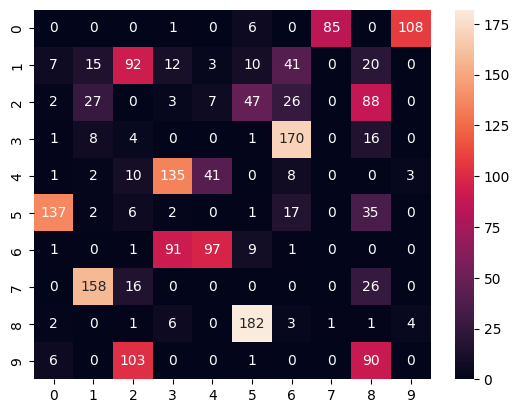

In [8]:
# Confusion matrix for m = 1.3
num_groups = u3_crisp.shape[1]
clusters3 = np.zeros((num_groups, num_groups))
rows = u3_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters3[h] = np.sum(u3_crisp[h*rows:(h+1)*rows], axis=0)
clusters3 = pd.DataFrame(clusters3.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters3, annot=True, fmt="d")

In [9]:
clusters3

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,1,0,6,0,85,0,108
1,7,15,92,12,3,10,41,0,20,0
2,2,27,0,3,7,47,26,0,88,0
3,1,8,4,0,0,1,170,0,16,0
4,1,2,10,135,41,0,8,0,0,3
5,137,2,6,2,0,1,17,0,35,0
6,1,0,1,91,97,9,1,0,0,0
7,0,158,16,0,0,0,0,0,26,0
8,2,0,1,6,0,182,3,1,1,4
9,6,0,103,0,0,1,0,0,90,0


### <a id='toc3_1_2_'></a>[Dataset 1](#toc0_)

In [29]:
n_clusters = 10
m = 1.3
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_1 = []
metrics_3_1 = []
best_loss = np.inf
best_index_1 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_1.fit(Xs[1], ys[1])
    metrics_3_1.append(kfcm_1.evaluate())
    model_arrays_1.append({
        "U": kfcm_1._U,
        "G": kfcm_1._G,
        "s": kfcm_1._s,
    })
    if metrics_3_1[i]["loss"] < best_loss:
        best_loss = metrics_3_1[i]["loss"]
        best_index_1 = i

-> Run 1/50
Iteration 1: J = 1354.3738575793707
{'accuracy': 0.47, 'MPC': 0.04810511488737623, 'rand': 0.2698824159676172, 'loss': 1354.3738575793707}
Iteration 2: J = 1308.5434858551978
{'accuracy': 0.5105, 'MPC': 0.03627547539027853, 'rand': 0.32500578014527637, 'loss': 1308.5434858551978}
Iteration 3: J = 1300.63537554836
{'accuracy': 0.499, 'MPC': 0.03279300290602516, 'rand': 0.3245678938087221, 'loss': 1300.63537554836}
Iteration 4: J = 1298.3282935529596
{'accuracy': 0.4705, 'MPC': 0.03218075432074685, 'rand': 0.2984181334658686, 'loss': 1298.3282935529596}
Iteration 5: J = 1297.4366151874794
{'accuracy': 0.46, 'MPC': 0.032619394479719954, 'rand': 0.28631433701008424, 'loss': 1297.4366151874794}
Iteration 6: J = 1296.9457745767354
{'accuracy': 0.4405, 'MPC': 0.033504171653060966, 'rand': 0.27114843546358847, 'loss': 1296.9457745767354}
Iteration 7: J = 1296.5421849788304
{'accuracy': 0.4245, 'MPC': 0.03477657262874978, 'rand': 0.251271957252158, 'loss': 1296.5421849788304}
Iterat

In [30]:
metrics_3_1

[{'accuracy': 0.3595,
  'MPC': 0.054215092924417174,
  'rand': 0.18748538239684445,
  'loss': 1293.4602469206038},
 {'accuracy': 0.3595,
  'MPC': 0.05421503400876704,
  'rand': 0.18748538239684445,
  'loss': 1293.4602462731095},
 {'accuracy': 0.3595,
  'MPC': 0.05421498316150075,
  'rand': 0.18748538239684445,
  'loss': 1293.4602462698576},
 {'accuracy': 0.3595,
  'MPC': 0.05421518334949582,
  'rand': 0.18748538239684445,
  'loss': 1293.46024661218},
 {'accuracy': 0.3595,
  'MPC': 0.05421525874018862,
  'rand': 0.18748538239684445,
  'loss': 1293.4602467540408},
 {'accuracy': 0.3595,
  'MPC': 0.05421526533975696,
  'rand': 0.18748538239684445,
  'loss': 1293.4602466594163},
 {'accuracy': 0.2775,
  'MPC': 0.02994712771629182,
  'rand': 0.14601818469703481,
  'loss': 1296.7953594209298},
 {'accuracy': 0.3595,
  'MPC': 0.05421497619775273,
  'rand': 0.18748538239684445,
  'loss': 1293.4602462775078},
 {'accuracy': 0.3595,
  'MPC': 0.05421523474094403,
  'rand': 0.18748538239684445,
  'los

In [31]:
best_index_1, metrics_3_1[best_index_1]

(46,
 {'accuracy': 0.3595,
  'MPC': 0.05421435744027692,
  'rand': 0.18748538239684445,
  'loss': 1293.4602462072144})

In [32]:
metrics_3_1[i]

{'accuracy': 0.3595,
 'MPC': 0.05421524401573452,
 'rand': 0.18748538239684445,
 'loss': 1293.4602464995587}

In [34]:
# Metrics for m = 1.3
acc_vec3_1 = [metrics_3_1[i]["accuracy"] for i in range(n_runs)]
rand_vec3_1 = [metrics_3_1[i]["rand"] for i in range(n_runs)]
mpc_vec3_1 = [metrics_3_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec3_1):.4f}" + u" \u00b1 " + f"{np.std(acc_vec3_1):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec3_1):.4f}" + u" \u00b1 " + f"{np.std(rand_vec3_1):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec3_1):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec3_1):.4f}")

Mean Accuracy: 0.3458 ± 0.0314
Mean Adjusted Rand Score: 0.1839 ± 0.0093
Mean MPC: 0.0491 ± 0.0117


In [36]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u3_1 = np.array(model_arrays_1[best_index_1]["U"])
u3_crisp_1 = np.zeros_like(best_u3_1)
for k in range(best_u3_1.shape[0]):
    max_index = np.argmax(best_u3_1[k])
    u3_crisp_1[k][max_index] = 1

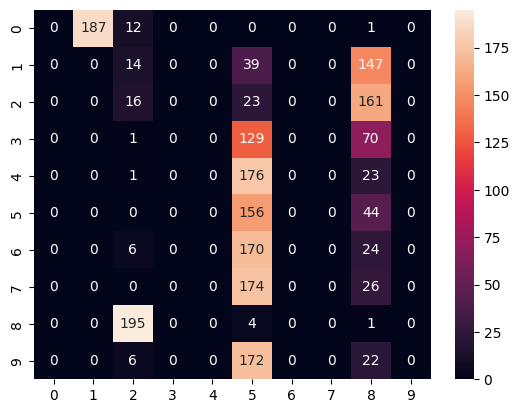

In [37]:
# Confusion matrix for m = 1.3
num_groups = u3_crisp_1.shape[1]
clusters3_1 = np.zeros((num_groups, num_groups))
rows = u3_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters3_1[h] = np.sum(u3_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters3_1 = pd.DataFrame(clusters3_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters3_1, annot=True, fmt="d")

In [38]:
clusters3_1

,0,1,2,3,4,5,6,7,8,9
0,0,187,12,0,0,0,0,0,1,0
1,0,0,14,0,0,39,0,0,147,0
2,0,0,16,0,0,23,0,0,161,0
3,0,0,1,0,0,129,0,0,70,0
4,0,0,1,0,0,176,0,0,23,0
5,0,0,0,0,0,156,0,0,44,0
6,0,0,6,0,0,170,0,0,24,0
7,0,0,0,0,0,174,0,0,26,0
8,0,0,195,0,0,4,0,0,1,0
9,0,0,6,0,0,172,0,0,22,0


In [50]:
np.savetxt("metrics_3_1_s.csv", model_arrays_1[best_index_1]["s"], delimiter=",")
np.savetxt("metrics_3_1_G.csv", model_arrays_1[best_index_1]["G"], delimiter=",")

### <a id='toc3_1_3_'></a>[Dataset 2](#toc0_)

In [40]:
n_clusters = 10
m = 1.3
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_2 = []
metrics_3_2 = []
best_loss = np.inf
best_index_2 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_2.fit(Xs[2], ys[2])
    metrics_3_2.append(kfcm_2.evaluate())
    model_arrays_2.append({
        "U": kfcm_2._U,
        "G": kfcm_2._G,
        "s": kfcm_2._s,
    })
    if metrics_3_2[i]["loss"] < best_loss:
        best_loss = metrics_3_2[i]["loss"]
        best_index_2 = i

-> Run 1/50
Iteration 1: J = 936.7561117996186
{'accuracy': 0.515, 'MPC': 0.16442013599975047, 'rand': 0.3099840755813407, 'loss': 936.7561117996186}
Iteration 2: J = 915.9561633062262
{'accuracy': 0.5155, 'MPC': 0.1659922501559824, 'rand': 0.309636725713131, 'loss': 915.9561633062262}
Iteration 3: J = 910.2364540323272
{'accuracy': 0.508, 'MPC': 0.17075611979564187, 'rand': 0.30505835733833875, 'loss': 910.2364540323272}
Iteration 4: J = 907.1714284278407
{'accuracy': 0.505, 'MPC': 0.17668530818032857, 'rand': 0.305020338883349, 'loss': 907.1714284278407}
Iteration 5: J = 904.9185672226369
{'accuracy': 0.51, 'MPC': 0.18345741233000112, 'rand': 0.3119360954963625, 'loss': 904.9185672226369}
Iteration 6: J = 902.9481053283578
{'accuracy': 0.5095, 'MPC': 0.1911113915138658, 'rand': 0.3127975380380059, 'loss': 902.9481053283578}
Iteration 7: J = 901.1105958807166
{'accuracy': 0.5175, 'MPC': 0.19940557851936347, 'rand': 0.3159932397210929, 'loss': 901.1105958807166}
Iteration 8: J = 899.37

In [41]:
best_index_2, metrics_3_2[best_index_2]

(5,
 {'accuracy': 0.531,
  'MPC': 0.2819913492266777,
  'rand': 0.35108820717266354,
  'loss': 880.6013425862841})

In [42]:
# Metrics for m = 1.3
acc_vec3_2 = [metrics_3_2[i]["accuracy"] for i in range(n_runs)]
rand_vec3_2 = [metrics_3_2[i]["rand"] for i in range(n_runs)]
mpc_vec3_2 = [metrics_3_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec3_2):.4f}" + u" \u00b1 " + f"{np.std(acc_vec3_2):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec3_2):.4f}" + u" \u00b1 " + f"{np.std(rand_vec3_2):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec3_2):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec3_2):.4f}")

Mean Accuracy: 0.5333 ± 0.0229
Mean Adjusted Rand Score: 0.3447 ± 0.0211
Mean MPC: 0.2803 ± 0.0059


In [43]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u3_2 = np.array(model_arrays_2[best_index_2]["U"])
u3_crisp_2 = np.zeros_like(best_u3_2)
for k in range(best_u3_2.shape[0]):
    max_index = np.argmax(best_u3_2[k])
    u3_crisp_2[k][max_index] = 1

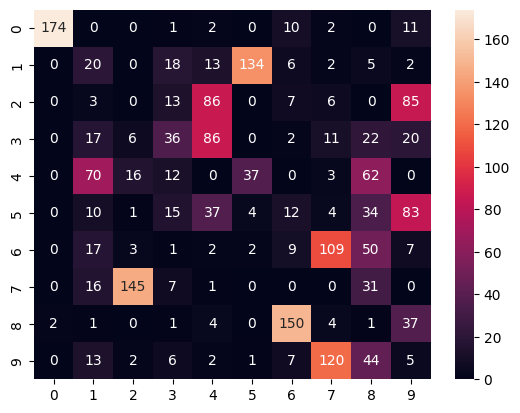

In [44]:
# Confusion matrix for m = 1.3
num_groups = u3_crisp_2.shape[1]
clusters3_2 = np.zeros((num_groups, num_groups))
rows = u3_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters3_2[h] = np.sum(u3_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters3_2 = pd.DataFrame(clusters3_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters3_2, annot=True, fmt="d")

In [45]:
clusters3_2

,0,1,2,3,4,5,6,7,8,9
0,174,0,0,1,2,0,10,2,0,11
1,0,20,0,18,13,134,6,2,5,2
2,0,3,0,13,86,0,7,6,0,85
3,0,17,6,36,86,0,2,11,22,20
4,0,70,16,12,0,37,0,3,62,0
5,0,10,1,15,37,4,12,4,34,83
6,0,17,3,1,2,2,9,109,50,7
7,0,16,145,7,1,0,0,0,31,0
8,2,1,0,1,4,0,150,4,1,37
9,0,13,2,6,2,1,7,120,44,5


In [51]:
np.savetxt("metrics_3_2_s.csv", model_arrays_2[best_index_2]["s"], delimiter=",")
np.savetxt("metrics_3_2_G.csv", model_arrays_2[best_index_2]["G"], delimiter=",")

## <a id='toc3_2_'></a>[m = 1.4](#toc0_)

### <a id='toc3_2_1_'></a>[Dataset 0](#toc0_)

In [52]:
n_clusters = 10
m = 1.4
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays = []
metrics_4 = []
best_loss = np.inf
best_index_4 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_4 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_4.fit(Xs[0], ys[0])
    metrics_4.append(kfcm_4.evaluate())
    model_arrays.append({
        "U": kfcm_4._U,
        "G": kfcm_4._G,
        "s": kfcm_4._s,
    })
    if metrics_4[i]["loss"] < best_loss:
        best_loss = metrics_4[i]["loss"]
        best_index_4 = i

-> Run 1/50
Iteration 1: J = 1514.834818056676
{'accuracy': 0.575, 'MPC': 0.029938233210426657, 'rand': 0.3933669798908093, 'loss': 1514.834818056676}
Iteration 2: J = 1501.7771230697667
{'accuracy': 0.6255, 'MPC': 0.03393707170584492, 'rand': 0.4316137548284853, 'loss': 1501.7771230697667}
Iteration 3: J = 1491.6712360245444
{'accuracy': 0.667, 'MPC': 0.03797693886472009, 'rand': 0.47232004024243535, 'loss': 1491.6712360245444}
Iteration 4: J = 1485.1852629031084
{'accuracy': 0.6865, 'MPC': 0.04082707090917681, 'rand': 0.4932526549731974, 'loss': 1485.1852629031084}
Iteration 5: J = 1481.379891074514
{'accuracy': 0.6995, 'MPC': 0.04253805488757856, 'rand': 0.5076520229536566, 'loss': 1481.379891074514}
Iteration 6: J = 1478.7942759664998
{'accuracy': 0.7075, 'MPC': 0.043709232390217845, 'rand': 0.5172069740846474, 'loss': 1478.7942759664998}
Iteration 7: J = 1476.9619600449405
{'accuracy': 0.7075, 'MPC': 0.044624532679454876, 'rand': 0.518464927306938, 'loss': 1476.9619600449405}
Iter

In [53]:
best_index_4, metrics_4[best_index_4]

(31,
 {'accuracy': 0.4795,
  'MPC': 0.026742077592419644,
  'rand': 0.2788875198810831,
  'loss': 1458.281724086069})

In [54]:
# Metrics for m = 1.3
acc_vec4 = [metrics_4[i]["accuracy"] for i in range(n_runs)]
rand_vec4 = [metrics_4[i]["rand"] for i in range(n_runs)]
mpc_vec4 = [metrics_4[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec4):.4f}" + u" \u00b1 " + f"{np.std(acc_vec4):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec4):.4f}" + u" \u00b1 " + f"{np.std(rand_vec4):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec4):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec4):.4f}")

Mean Accuracy: 0.6133 ± 0.0528
Mean Adjusted Rand Score: 0.4206 ± 0.0624
Mean MPC: 0.0412 ± 0.0067


In [55]:
# Crisp partition of the best result for m = 1.3
#best_u4 = pd.DataFrame(u3[best_j3])
best_u4 = np.array(model_arrays[best_index_4]["U"])
u4_crisp = np.zeros_like(best_u4)
for k in range(best_u4.shape[0]):
    max_index = np.argmax(best_u4[k])
    u4_crisp[k][max_index] = 1

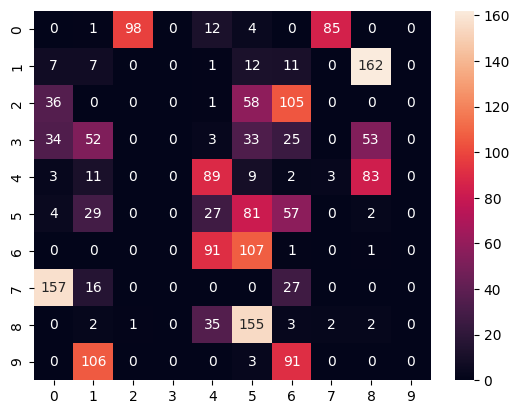

In [56]:
# Confusion matrix for m = 1.3
num_groups = u4_crisp.shape[1]
clusters4 = np.zeros((num_groups, num_groups))
rows = u4_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters4[h] = np.sum(u4_crisp[h*rows:(h+1)*rows], axis=0)
clusters4 = pd.DataFrame(clusters4.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters4, annot=True, fmt="d")

In [57]:
clusters4

,0,1,2,3,4,5,6,7,8,9
0,0,1,98,0,12,4,0,85,0,0
1,7,7,0,0,1,12,11,0,162,0
2,36,0,0,0,1,58,105,0,0,0
3,34,52,0,0,3,33,25,0,53,0
4,3,11,0,0,89,9,2,3,83,0
5,4,29,0,0,27,81,57,0,2,0
6,0,0,0,0,91,107,1,0,1,0
7,157,16,0,0,0,0,27,0,0,0
8,0,2,1,0,35,155,3,2,2,0
9,0,106,0,0,0,3,91,0,0,0


In [58]:
np.savetxt("metrics_4_s.csv", model_arrays[best_index_4]["s"], delimiter=",")
np.savetxt("metrics_4_G.csv", model_arrays[best_index_4]["G"], delimiter=",")

### <a id='toc3_2_2_'></a>[Dataset 1](#toc0_)

In [59]:
n_clusters = 10
m = 1.4
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_4_1 = []
metrics_4_1 = []
best_loss = np.inf
best_index_4_1 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_4_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_4_1.fit(Xs[1], ys[1])
    metrics_4_1.append(kfcm_4_1.evaluate())
    model_arrays_4_1.append({
        "U": kfcm_4_1._U,
        "G": kfcm_4_1._G,
        "s": kfcm_4_1._s,
    })
    if metrics_4_1[i]["loss"] < best_loss:
        best_loss = metrics_4_1[i]["loss"]
        best_index_4_1 = i

-> Run 1/50
Iteration 1: J = 1085.617568258052
{'accuracy': 0.455, 'MPC': 0.024784891908417928, 'rand': 0.25879746542746496, 'loss': 1085.617568258052}
Iteration 2: J = 1043.401398417421
{'accuracy': 0.4835, 'MPC': 0.016156405846328714, 'rand': 0.30035719098041136, 'loss': 1043.401398417421}
Iteration 3: J = 1037.504378889617
{'accuracy': 0.43, 'MPC': 0.013475250043167852, 'rand': 0.2531452284538207, 'loss': 1037.504378889617}
Iteration 4: J = 1036.1819384998375
{'accuracy': 0.38, 'MPC': 0.0124808578372686, 'rand': 0.21881911923028904, 'loss': 1036.1819384998375}
Iteration 5: J = 1035.737264142626
{'accuracy': 0.335, 'MPC': 0.012101188872660429, 'rand': 0.18387681583931662, 'loss': 1035.737264142626}
Iteration 6: J = 1035.5226996000092
{'accuracy': 0.3045, 'MPC': 0.011976588029753543, 'rand': 0.16314385266834094, 'loss': 1035.5226996000092}
Iteration 7: J = 1035.396787805604
{'accuracy': 0.289, 'MPC': 0.011967454025586743, 'rand': 0.16353254530580222, 'loss': 1035.396787805604}
Iterati

In [60]:
best_index_4_1, metrics_4_1[best_index_4_1]

(38,
 {'accuracy': 0.2685,
  'MPC': 0.005362153911513845,
  'rand': 0.1620231983856257,
  'loss': 1034.827217256396})

In [61]:
# Metrics for m = 1.3
acc_vec4_1 = [metrics_4_1[i]["accuracy"] for i in range(n_runs)]
rand_vec4_1 = [metrics_4_1[i]["rand"] for i in range(n_runs)]
mpc_vec4_1 = [metrics_4_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec4_1):.4f}" + u" \u00b1 " + f"{np.std(acc_vec4_1):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec4_1):.4f}" + u" \u00b1 " + f"{np.std(rand_vec4_1):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec4_1):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec4_1):.4f}")

Mean Accuracy: 0.2664 ± 0.0229
Mean Adjusted Rand Score: 0.1533 ± 0.0151
Mean MPC: 0.0092 ± 0.0050


In [62]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u4_1 = np.array(model_arrays_4_1[best_index_4_1]["U"])
u4_crisp_1 = np.zeros_like(best_u4_1)
for k in range(best_u4_1.shape[0]):
    max_index = np.argmax(best_u4_1[k])
    u4_crisp_1[k][max_index] = 1

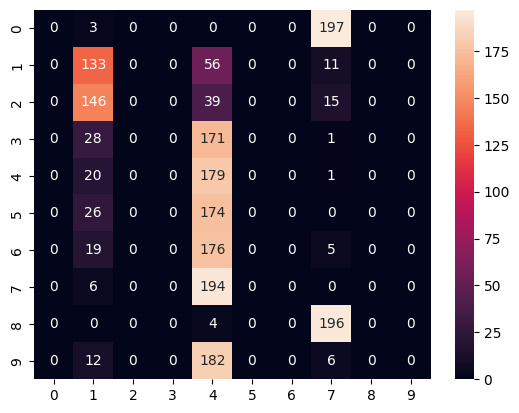

In [63]:
# Confusion matrix for m = 1.3
num_groups = u4_crisp_1.shape[1]
clusters4_1 = np.zeros((num_groups, num_groups))
rows = u4_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters4_1[h] = np.sum(u4_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters4_1 = pd.DataFrame(clusters4_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters4_1, annot=True, fmt="d")

In [64]:
clusters4_1

,0,1,2,3,4,5,6,7,8,9
0,0,3,0,0,0,0,0,197,0,0
1,0,133,0,0,56,0,0,11,0,0
2,0,146,0,0,39,0,0,15,0,0
3,0,28,0,0,171,0,0,1,0,0
4,0,20,0,0,179,0,0,1,0,0
5,0,26,0,0,174,0,0,0,0,0
6,0,19,0,0,176,0,0,5,0,0
7,0,6,0,0,194,0,0,0,0,0
8,0,0,0,0,4,0,0,196,0,0
9,0,12,0,0,182,0,0,6,0,0


In [65]:
np.savetxt("metrics_4_1_s.csv", model_arrays_4_1[best_index_4_1]["s"], delimiter=",")
np.savetxt("metrics_4_1_G.csv", model_arrays_4_1[best_index_4_1]["G"], delimiter=",")

### <a id='toc3_2_3_'></a>[Dataset 2](#toc0_)

In [66]:
n_clusters = 10
m = 1.4
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_4_2 = []
metrics_4_2 = []
best_loss = np.inf
best_index_4_2 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_4_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_4_2.fit(Xs[2], ys[2])
    metrics_4_2.append(kfcm_4_2.evaluate())
    model_arrays_4_2.append({
        "U": kfcm_4_2._U,
        "G": kfcm_4_2._G,
        "s": kfcm_4_2._s,
    })
    if metrics_4_2[i]["loss"] < best_loss:
        best_loss = metrics_4_2[i]["loss"]
        best_index_4_2 = i

-> Run 1/50
Iteration 1: J = 763.7493339134604
{'accuracy': 0.5125, 'MPC': 0.09393445200508521, 'rand': 0.3102972512419635, 'loss': 763.7493339134604}
Iteration 2: J = 746.2699310518909
{'accuracy': 0.5005, 'MPC': 0.08799734945096349, 'rand': 0.3033135776237867, 'loss': 746.2699310518909}
Iteration 3: J = 742.1319600820993
{'accuracy': 0.492, 'MPC': 0.08662818785636306, 'rand': 0.2962321283866805, 'loss': 742.1319600820993}
Iteration 4: J = 740.4739238554337
{'accuracy': 0.4905, 'MPC': 0.08724988569379721, 'rand': 0.2988703064475755, 'loss': 740.4739238554337}
Iteration 5: J = 739.6214844765498
{'accuracy': 0.4875, 'MPC': 0.0886556392660457, 'rand': 0.29999003680396896, 'loss': 739.6214844765498}
Iteration 6: J = 739.1194656508098
{'accuracy': 0.4895, 'MPC': 0.09022467973288673, 'rand': 0.3012289591267514, 'loss': 739.1194656508098}
Iteration 7: J = 738.8016191883364
{'accuracy': 0.4885, 'MPC': 0.09165085716430965, 'rand': 0.30208990176084227, 'loss': 738.8016191883364}
Iteration 8: J 

In [67]:
best_index_4_2, metrics_4_2[best_index_4_2]

(44,
 {'accuracy': 0.513,
  'MPC': 0.1455494622478678,
  'rand': 0.3299547228371059,
  'loss': 732.3514643049356})

In [68]:
# Metrics for m = 1.3
acc_vec4_2 = [metrics_4_2[i]["accuracy"] for i in range(n_runs)]
rand_vec4_2 = [metrics_4_2[i]["rand"] for i in range(n_runs)]
mpc_vec4_2 = [metrics_4_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec4_2):.4f}" + u" \u00b1 " + f"{np.std(acc_vec4_2):.4f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec4_2):.4f}" + u" \u00b1 " + f"{np.std(rand_vec4_2):.4f}")
print(f"Mean MPC: {np.mean(mpc_vec4_2):.4f}" + u" \u00b1 " + f"{np.std(mpc_vec4_2):.4f}")

Mean Accuracy: 0.4931 ± 0.0269
Mean Adjusted Rand Score: 0.3209 ± 0.0120
Mean MPC: 0.1354 ± 0.0111


In [69]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNV
best_u4_2 = np.array(model_arrays_4_2[best_index_4_2]["U"])
u4_crisp_2 = np.zeros_like(best_u4_2)
for k in range(best_u4_2.shape[0]):
    max_index = np.argmax(best_u4_2[k])
    u4_crisp_2[k][max_index] = 1

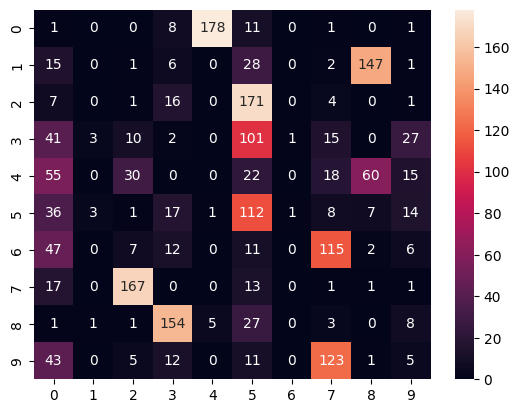

In [70]:
# Confusion matrix for m = 1.3
num_groups = u4_crisp_2.shape[1]
clusters4_2 = np.zeros((num_groups, num_groups))
rows = u4_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters4_2[h] = np.sum(u4_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters4_2 = pd.DataFrame(clusters4_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters4_2, annot=True, fmt="d")

In [71]:
clusters4_2

,0,1,2,3,4,5,6,7,8,9
0,1,0,0,8,178,11,0,1,0,1
1,15,0,1,6,0,28,0,2,147,1
2,7,0,1,16,0,171,0,4,0,1
3,41,3,10,2,0,101,1,15,0,27
4,55,0,30,0,0,22,0,18,60,15
5,36,3,1,17,1,112,1,8,7,14
6,47,0,7,12,0,11,0,115,2,6
7,17,0,167,0,0,13,0,1,1,1
8,1,1,1,154,5,27,0,3,0,8
9,43,0,5,12,0,11,0,123,1,5


In [72]:
np.savetxt("metrics_4_2_s.csv", model_arrays_4_2[best_index_4_2]["s"], delimiter=",")
np.savetxt("metrics_4_2_G.csv", model_arrays_4_2[best_index_4_2]["G"], delimiter=",")

## <a id='toc3_3_'></a>[m = 1.5](#toc0_)

### <a id='toc3_3_1_'></a>[Dataset 0](#toc0_)

In [73]:
n_clusters = 10
m = 1.5
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays_5 = []
metrics_5 = []
best_loss = np.inf
best_index_5 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_5 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_5.fit(Xs[0], ys[0])
    metrics_5.append(kfcm_5.evaluate())
    model_arrays_5.append({
        "U": kfcm_5._U,
        "G": kfcm_5._G,
        "s": kfcm_5._s,
    })
    if metrics_5[i]["loss"] < best_loss:
        best_loss = metrics_5[i]["loss"]
        best_index_5 = i

-> Run 1/50
Iteration 1: J = 1209.9956148689084
{'accuracy': 0.575, 'MPC': 0.017775273524421764, 'rand': 0.39352568066387605, 'loss': 1209.9956148689084}
Iteration 2: J = 1200.7388650066318
{'accuracy': 0.623, 'MPC': 0.018869115770897116, 'rand': 0.4297163428673237, 'loss': 1200.7388650066318}
Iteration 3: J = 1192.7402028934905
{'accuracy': 0.6675, 'MPC': 0.021022293823040883, 'rand': 0.47715209584153734, 'loss': 1192.7402028934905}
Iteration 4: J = 1187.812960645961
{'accuracy': 0.684, 'MPC': 0.022722970671807396, 'rand': 0.49116016343861085, 'loss': 1187.812960645961}
Iteration 5: J = 1184.9982719552613
{'accuracy': 0.6975, 'MPC': 0.023728145019487723, 'rand': 0.5026420795045388, 'loss': 1184.9982719552613}
Iteration 6: J = 1183.1084021098068
{'accuracy': 0.7025, 'MPC': 0.024357486671529704, 'rand': 0.5094897797866381, 'loss': 1183.1084021098068}
Iteration 7: J = 1181.8019520578418
{'accuracy': 0.702, 'MPC': 0.024810570518859376, 'rand': 0.5086391824133343, 'loss': 1181.801952057841

In [74]:
best_index_5, metrics_5[best_index_5]

(31,
 {'accuracy': 0.4445,
  'MPC': 0.01521917197823508,
  'rand': 0.26453517016294825,
  'loss': 1163.8303386782254})

In [75]:
# Metrics for m = 1.3
acc_vec5 = [metrics_5[i]["accuracy"] for i in range(n_runs)]
rand_vec5 = [metrics_5[i]["rand"] for i in range(n_runs)]
mpc_vec5 = [metrics_5[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec5):.5f}" + u" \u00b1 " + f"{np.std(acc_vec5):.5f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec5):.5f}" + u" \u00b1 " + f"{np.std(rand_vec5):.5f}")
print(f"Mean MPC: {np.mean(mpc_vec5):.5f}" + u" \u00b1 " + f"{np.std(mpc_vec5):.5f}")

Mean Accuracy: 0.59093 ± 0.05579
Mean Adjusted Rand Score: 0.40316 ± 0.06298
Mean MPC: 0.02375 ± 0.00376


In [76]:
# Crisp partition of the best result for m = 1.3
#best_u5 = pd.DataFrame(u3[best_j3])
#RODA DE NOVO
best_u5 = np.array(model_arrays_5[best_index_5]["U"])
u5_crisp = np.zeros_like(best_u5)
for k in range(best_u5.shape[0]):
    max_index = np.argmax(best_u5[k])
    u5_crisp[k][max_index] = 1

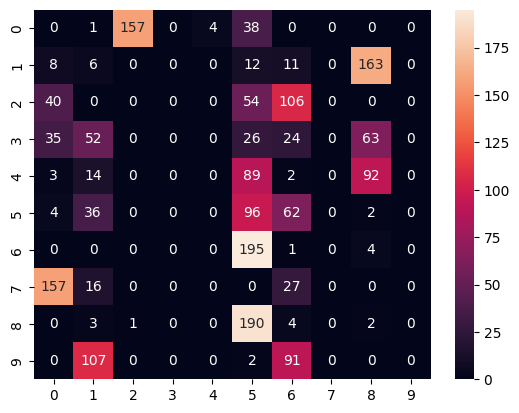

In [77]:
# Confusion matrix for m = 1.3
num_groups = u5_crisp.shape[1]
clusters5 = np.zeros((num_groups, num_groups))
rows = u5_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters5[h] = np.sum(u5_crisp[h*rows:(h+1)*rows], axis=0)
clusters5 = pd.DataFrame(clusters5.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters5, annot=True, fmt="d")

In [78]:
clusters5

,0,1,2,3,4,5,6,7,8,9
0,0,1,157,0,4,38,0,0,0,0
1,8,6,0,0,0,12,11,0,163,0
2,40,0,0,0,0,54,106,0,0,0
3,35,52,0,0,0,26,24,0,63,0
4,3,14,0,0,0,89,2,0,92,0
5,4,36,0,0,0,96,62,0,2,0
6,0,0,0,0,0,195,1,0,4,0
7,157,16,0,0,0,0,27,0,0,0
8,0,3,1,0,0,190,4,0,2,0
9,0,107,0,0,0,2,91,0,0,0


In [79]:
np.savetxt("metrics_5_s.csv", model_arrays_5[best_index_5]["s"], delimiter=",")
np.savetxt("metrics_5_G.csv", model_arrays_5[best_index_5]["G"], delimiter=",")

### <a id='toc3_3_2_'></a>[Dataset 1](#toc0_)

In [80]:
n_clusters = 10
m = 1.5
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_5_1 = []
metrics_5_1 = []
best_loss = np.inf
best_index_5_1 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_5_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_5_1.fit(Xs[1], ys[1])
    metrics_5_1.append(kfcm_5_1.evaluate())
    model_arrays_5_1.append({
        "U": kfcm_5_1._U,
        "G": kfcm_5_1._G,
        "s": kfcm_5_1._s,
    })
    if metrics_5_1[i]["loss"] < best_loss:
        best_loss = metrics_5_1[i]["loss"]
        best_index_5_1 = i

-> Run 1/50
Iteration 1: J = 868.3152922515308
{'accuracy': 0.4475, 'MPC': 0.014413791703579593, 'rand': 0.2530596123987686, 'loss': 868.3152922515308}
Iteration 2: J = 830.4059039224956
{'accuracy': 0.453, 'MPC': 0.00789469480302607, 'rand': 0.28547607069840236, 'loss': 830.4059039224956}
Iteration 3: J = 825.4626482904994
{'accuracy': 0.3765, 'MPC': 0.005669814782825688, 'rand': 0.23917223486755207, 'loss': 825.4626482904994}
Iteration 4: J = 824.3131490661715
{'accuracy': 0.342, 'MPC': 0.004488038777025083, 'rand': 0.2080289653559006, 'loss': 824.3131490661715}
Iteration 5: J = 823.8076732665002
{'accuracy': 0.3055, 'MPC': 0.0036781834317966, 'rand': 0.18402893062398104, 'loss': 823.8076732665002}
Iteration 6: J = 823.4672477563813
{'accuracy': 0.29, 'MPC': 0.003056386395538402, 'rand': 0.17976780583384466, 'loss': 823.4672477563813}
Iteration 7: J = 823.1982175853823
{'accuracy': 0.2845, 'MPC': 0.0025621239515213334, 'rand': 0.17149553090337477, 'loss': 823.1982175853823}
Iteration

In [81]:
best_index_5_1, metrics_5_1[best_index_5_1]

(31,
 {'accuracy': 0.1995,
  'MPC': 8.892344638411487e-10,
  'rand': 0.1091399941264112,
  'loss': 822.0516620865368})

In [82]:
# Metrics for m = 1.3
acc_vec5_1 = [metrics_5_1[i]["accuracy"] for i in range(n_runs)]
rand_vec5_1 = [metrics_5_1[i]["rand"] for i in range(n_runs)]
mpc_vec5_1 = [metrics_5_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec5_1):.5f}" + u" \u00b1 " + f"{np.std(acc_vec5_1):.5f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec5_1):.5f}" + u" \u00b1 " + f"{np.std(rand_vec5_1):.5f}")
print(f"Mean MPC: {np.mean(mpc_vec5_1):.5f}" + u" \u00b1 " + f"{np.std(mpc_vec5_1):.5f}")

Mean Accuracy: 0.19956 ± 0.00016
Mean Adjusted Rand Score: 0.10916 ± 0.00005
Mean MPC: 0.00000 ± 0.00000


In [83]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNVB
best_u5_1 = np.array(model_arrays_5_1[best_index_5_1]["U"])
u5_crisp_1 = np.zeros_like(best_u5_1)
for k in range(best_u5_1.shape[0]):
    max_index = np.argmax(best_u5_1[k])
    u5_crisp_1[k][max_index] = 1

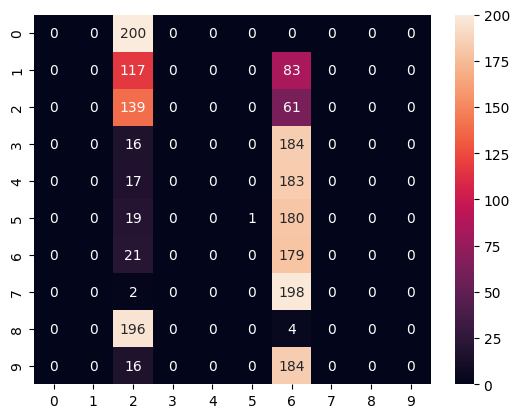

In [84]:
# Confusion matrix for m = 1.3
num_groups = u5_crisp_1.shape[1]
clusters5_1 = np.zeros((num_groups, num_groups))
rows = u5_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters5_1[h] = np.sum(u5_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters5_1 = pd.DataFrame(clusters5_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters5_1, annot=True, fmt="d")

In [85]:
clusters5_1

,0,1,2,3,4,5,6,7,8,9
0,0,0,200,0,0,0,0,0,0,0
1,0,0,117,0,0,0,83,0,0,0
2,0,0,139,0,0,0,61,0,0,0
3,0,0,16,0,0,0,184,0,0,0
4,0,0,17,0,0,0,183,0,0,0
5,0,0,19,0,0,1,180,0,0,0
6,0,0,21,0,0,0,179,0,0,0
7,0,0,2,0,0,0,198,0,0,0
8,0,0,196,0,0,0,4,0,0,0
9,0,0,16,0,0,0,184,0,0,0


In [86]:
np.savetxt("metrics_5_1_s.csv", model_arrays_5_1[best_index_5_1]["s"], delimiter=",")
np.savetxt("metrics_5_1_G.csv", model_arrays_5_1[best_index_5_1]["G"], delimiter=",")

### <a id='toc3_3_3_'></a>[Dataset 2](#toc0_)

In [87]:
n_clusters = 10
m = 1.5
max_iter = 100
tol = 1e-6

n_runs = 50

model_arrays_5_2 = []
metrics_5_2 = []
best_loss = np.inf
best_index_5_2 = None
for i in range(n_runs):
    print("="*50)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_5_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_5_2.fit(Xs[2], ys[2])
    metrics_5_2.append(kfcm_5_2.evaluate())
    model_arrays_5_2.append({
        "U": kfcm_5_2._U,
        "G": kfcm_5_2._G,
        "s": kfcm_5_2._s,
    })
    if metrics_5_2[i]["loss"] < best_loss:
        best_loss = metrics_5_2[i]["loss"]
        best_index_5_2 = i

-> Run 1/50
Iteration 1: J = 616.1126631925176
{'accuracy': 0.51, 'MPC': 0.0567271987549447, 'rand': 0.30823497313270815, 'loss': 616.1126631925176}
Iteration 2: J = 600.6353202136142
{'accuracy': 0.4905, 'MPC': 0.04962114686671215, 'rand': 0.2950050401694781, 'loss': 600.6353202136142}
Iteration 3: J = 597.2877940966193
{'accuracy': 0.474, 'MPC': 0.04660163919874538, 'rand': 0.2812136112758455, 'loss': 597.2877940966193}
Iteration 4: J = 596.1874773950364
{'accuracy': 0.468, 'MPC': 0.04522184464229295, 'rand': 0.2800521908392714, 'loss': 596.1874773950364}
Iteration 5: J = 595.7166314186
{'accuracy': 0.4665, 'MPC': 0.044554145644750576, 'rand': 0.27996437184470113, 'loss': 595.7166314186}
Iteration 6: J = 595.4695179320677
{'accuracy': 0.4605, 'MPC': 0.044236317574828155, 'rand': 0.2735720313595859, 'loss': 595.4695179320677}
Iteration 7: J = 595.3183914268891
{'accuracy': 0.4535, 'MPC': 0.044111000133628786, 'rand': 0.2655392895587747, 'loss': 595.3183914268891}
Iteration 8: J = 595.

In [88]:
best_index_5_2, metrics_5_2[best_index_5_2]

(21,
 {'accuracy': 0.2975,
  'MPC': 0.040028762798350326,
  'rand': 0.1652828785822305,
  'loss': 594.566832198349})

In [89]:
# Metrics for m = 1.3
acc_vec5_2 = [metrics_5_2[i]["accuracy"] for i in range(n_runs)]
rand_vec5_2 = [metrics_5_2[i]["rand"] for i in range(n_runs)]
mpc_vec5_2 = [metrics_5_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec5_2):.5f}" + u" \u00b1 " + f"{np.std(acc_vec5_2):.5f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec5_2):.5f}" + u" \u00b1 " + f"{np.std(rand_vec5_2):.5f}")
print(f"Mean MPC: {np.mean(mpc_vec5_2):.5f}" + u" \u00b1 " + f"{np.std(mpc_vec5_2):.5f}")

Mean Accuracy: 0.36166 ± 0.02905
Mean Adjusted Rand Score: 0.20620 ± 0.02558
Mean MPC: 0.05072 ± 0.00830


In [90]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u5_2 = np.array(model_arrays_5_2[best_index_5_2]["U"])
u5_crisp_2 = np.zeros_like(best_u5_2)
for k in range(best_u5_2.shape[0]):
    max_index = np.argmax(best_u5_2[k])
    u5_crisp_2[k][max_index] = 1

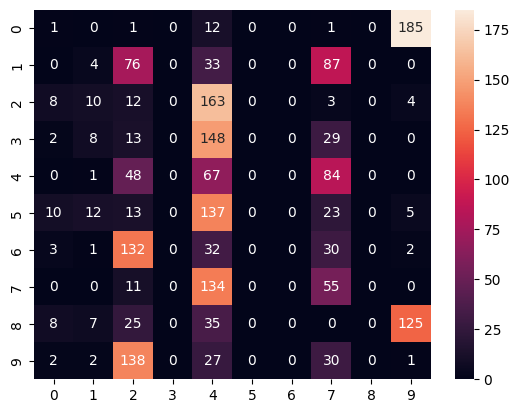

In [91]:
# Confusion matrix for m = 1.3
num_groups = u5_crisp_2.shape[1]
clusters5_2 = np.zeros((num_groups, num_groups))
rows = u5_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters5_2[h] = np.sum(u5_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters5_2 = pd.DataFrame(clusters5_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters5_2, annot=True, fmt="d")

In [92]:
clusters5_2

,0,1,2,3,4,5,6,7,8,9
0,1,0,1,0,12,0,0,1,0,185
1,0,4,76,0,33,0,0,87,0,0
2,8,10,12,0,163,0,0,3,0,4
3,2,8,13,0,148,0,0,29,0,0
4,0,1,48,0,67,0,0,84,0,0
5,10,12,13,0,137,0,0,23,0,5
6,3,1,132,0,32,0,0,30,0,2
7,0,0,11,0,134,0,0,55,0,0
8,8,7,25,0,35,0,0,0,0,125
9,2,2,138,0,27,0,0,30,0,1


In [93]:
np.savetxt("metrics_5_2_s.csv", model_arrays_5_2[best_index_5_2]["s"], delimiter=",")
np.savetxt("metrics_5_2_G.csv", model_arrays_5_2[best_index_5_2]["G"], delimiter=",")

## <a id='toc3_4_'></a>[m = 1.6](#toc0_)

### <a id='toc3_4_1_'></a>[Dataset 0](#toc0_)

In [94]:
n_clusters = 10
m = 1.6
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays_6 = []
metrics_6 = []
best_loss = np.inf
best_index_6 = None
for i in range(n_runs):
    print("="*60)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_6 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_6.fit(Xs[0], ys[0])
    metrics_6.append(kfcm_6.evaluate())
    model_arrays_6.append({
        "U": kfcm_6._U,
        "G": kfcm_6._G,
        "s": kfcm_6._s,
    })
    if metrics_6[i]["loss"] < best_loss:
        best_loss = metrics_6[i]["loss"]
        best_index_6 = i

-> Run 1/50
Iteration 1: J = 964.8697757993043
{'accuracy': 0.5725, 'MPC': 0.011583371496791561, 'rand': 0.3914393066448297, 'loss': 964.8697757993043}
Iteration 2: J = 958.1294201481916
{'accuracy': 0.615, 'MPC': 0.011433816424209375, 'rand': 0.4234294107051977, 'loss': 958.1294201481916}
Iteration 3: J = 951.748363382942
{'accuracy': 0.6655, 'MPC': 0.01247579646947572, 'rand': 0.47589516108954816, 'loss': 951.748363382942}
Iteration 4: J = 947.7571586651434
{'accuracy': 0.683, 'MPC': 0.013556364839676815, 'rand': 0.4928105405988595, 'loss': 947.7571586651434}
Iteration 5: J = 945.5647442104896
{'accuracy': 0.6955, 'MPC': 0.014191057392928808, 'rand': 0.4994143237541349, 'loss': 945.5647442104896}
Iteration 6: J = 944.1075708935687
{'accuracy': 0.6975, 'MPC': 0.014568842708935548, 'rand': 0.5014412923740924, 'loss': 944.1075708935687}
Iteration 7: J = 943.1126790200865
{'accuracy': 0.6965, 'MPC': 0.014851885452295432, 'rand': 0.4999372483894906, 'loss': 943.1126790200865}
Iteration 8:

In [95]:
best_index_6, metrics_6[best_index_6]

(31,
 {'accuracy': 0.445,
  'MPC': 0.009928207296196256,
  'rand': 0.2660542480912054,
  'loss': 927.3584965165454})

In [96]:
# Metrics for m = 1.3
acc_vec6 = [metrics_6[i]["accuracy"] for i in range(n_runs)]
rand_vec6 = [metrics_6[i]["rand"] for i in range(n_runs)]
mpc_vec6 = [metrics_6[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec6):.6f}" + u" \u00b1 " + f"{np.std(acc_vec6):.6f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec6):.6f}" + u" \u00b1 " + f"{np.std(rand_vec6):.6f}")
print(f"Mean MPC: {np.mean(mpc_vec6):.6f}" + u" \u00b1 " + f"{np.std(mpc_vec6):.6f}")

Mean Accuracy: 0.586150 ± 0.058366
Mean Adjusted Rand Score: 0.398073 ± 0.061409
Mean MPC: 0.014805 ± 0.002176


In [97]:
# Crisp partition of the best result for m = 1.3
#best_u6 = pd.DataFrame(u3[best_j3])
#RODA DE NOVO
best_u6 = np.array(model_arrays_6[best_index_6]["U"])
u6_crisp = np.zeros_like(best_u6)
for k in range(best_u6.shape[0]):
    max_index = np.argmax(best_u6[k])
    u6_crisp[k][max_index] = 1

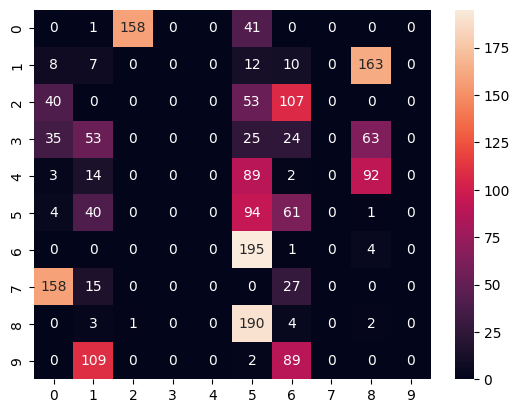

In [98]:
# Confusion matrix for m = 1.3
num_groups = u6_crisp.shape[1]
clusters6 = np.zeros((num_groups, num_groups))
rows = u6_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters6[h] = np.sum(u6_crisp[h*rows:(h+1)*rows], axis=0)
clusters6 = pd.DataFrame(clusters6.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters6, annot=True, fmt="d")

In [99]:
clusters6

,0,1,2,3,4,5,6,7,8,9
0,0,1,158,0,0,41,0,0,0,0
1,8,7,0,0,0,12,10,0,163,0
2,40,0,0,0,0,53,107,0,0,0
3,35,53,0,0,0,25,24,0,63,0
4,3,14,0,0,0,89,2,0,92,0
5,4,40,0,0,0,94,61,0,1,0
6,0,0,0,0,0,195,1,0,4,0
7,158,15,0,0,0,0,27,0,0,0
8,0,3,1,0,0,190,4,0,2,0
9,0,109,0,0,0,2,89,0,0,0


In [100]:
np.savetxt("metrics_6_s.csv", model_arrays_6[best_index_6]["s"], delimiter=",")
np.savetxt("metrics_6_G.csv", model_arrays_6[best_index_6]["G"], delimiter=",")

### <a id='toc3_4_2_'></a>[Dataset 1](#toc0_)

In [101]:
n_clusters = 10
m = 1.6
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_6_1 = []
metrics_6_1 = []
best_loss = np.inf
best_index_6_1 = None
for i in range(n_runs):
    print("="*60)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_6_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_6_1.fit(Xs[1], ys[1])
    metrics_6_1.append(kfcm_6_1.evaluate())
    model_arrays_6_1.append({
        "U": kfcm_6_1._U,
        "G": kfcm_6_1._G,
        "s": kfcm_6_1._s,
    })
    if metrics_6_1[i]["loss"] < best_loss:
        best_loss = metrics_6_1[i]["loss"]
        best_index_6_1 = i

-> Run 1/50
Iteration 1: J = 694.1671775607231
{'accuracy': 0.4365, 'MPC': 0.009406660305325776, 'rand': 0.24631982419273382, 'loss': 694.1671775607231}
Iteration 2: J = 660.4042779246839
{'accuracy': 0.4285, 'MPC': 0.004396537545008128, 'rand': 0.2826881313080682, 'loss': 660.4042779246839}
Iteration 3: J = 655.9100052098123
{'accuracy': 0.3705, 'MPC': 0.002717520941216134, 'rand': 0.2429478000225647, 'loss': 655.9100052098123}
Iteration 4: J = 654.7515943353162
{'accuracy': 0.327, 'MPC': 0.0018470504788770103, 'rand': 0.19643937355337754, 'loss': 654.7515943353162}
Iteration 5: J = 654.1703253315077
{'accuracy': 0.291, 'MPC': 0.001295962487655733, 'rand': 0.17940307160157165, 'loss': 654.1703253315077}
Iteration 6: J = 653.8044758503519
{'accuracy': 0.2795, 'MPC': 0.0009160474091840509, 'rand': 0.16696010865174338, 'loss': 653.8044758503519}
Iteration 7: J = 653.5648470577567
{'accuracy': 0.2695, 'MPC': 0.0006403217920268878, 'rand': 0.15646939105339, 'loss': 653.5648470577567}
Itera

In [102]:
best_index_6_1, metrics_6_1[best_index_6_1]

(9,
 {'accuracy': 0.199,
  'MPC': 3.7461789226256315e-10,
  'rand': 0.10930969128984641,
  'loss': 652.9788454104995})

In [103]:
# Metrics for m = 1.3
acc_vec6_1 = [metrics_6_1[i]["accuracy"] for i in range(n_runs)]
rand_vec6_1 = [metrics_6_1[i]["rand"] for i in range(n_runs)]
mpc_vec6_1 = [metrics_6_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec6_1):.6f}" + u" \u00b1 " + f"{np.std(acc_vec6_1):.6f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec6_1):.6f}" + u" \u00b1 " + f"{np.std(rand_vec6_1):.6f}")
print(f"Mean MPC: {np.mean(mpc_vec6_1):.6f}" + u" \u00b1 " + f"{np.std(mpc_vec6_1):.6f}")

Mean Accuracy: 0.199000 ± 0.000000
Mean Adjusted Rand Score: 0.109310 ± 0.000000
Mean MPC: 0.000000 ± 0.000000


In [104]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNVB
best_u6_1 = np.array(model_arrays_6_1[best_index_6_1]["U"])
u6_crisp_1 = np.zeros_like(best_u6_1)
for k in range(best_u6_1.shape[0]):
    max_index = np.argmax(best_u6_1[k])
    u6_crisp_1[k][max_index] = 1

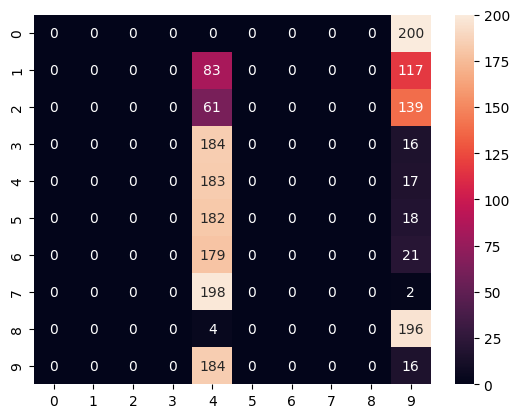

In [105]:
# Confusion matrix for m = 1.3
num_groups = u6_crisp_1.shape[1]
clusters6_1 = np.zeros((num_groups, num_groups))
rows = u6_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters6_1[h] = np.sum(u6_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters6_1 = pd.DataFrame(clusters6_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters6_1, annot=True, fmt="d")

In [106]:
clusters6_1

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,0,0,0,0,0,0,200
1,0,0,0,0,83,0,0,0,0,117
2,0,0,0,0,61,0,0,0,0,139
3,0,0,0,0,184,0,0,0,0,16
4,0,0,0,0,183,0,0,0,0,17
5,0,0,0,0,182,0,0,0,0,18
6,0,0,0,0,179,0,0,0,0,21
7,0,0,0,0,198,0,0,0,0,2
8,0,0,0,0,4,0,0,0,0,196
9,0,0,0,0,184,0,0,0,0,16


In [107]:
np.savetxt("metrics_6_1_s.csv", model_arrays_6_1[best_index_6_1]["s"], delimiter=",")
np.savetxt("metrics_6_1_G.csv", model_arrays_6_1[best_index_6_1]["G"], delimiter=",")

### <a id='toc3_4_3_'></a>[Dataset 2](#toc0_)

In [108]:
n_clusters = 10
m = 1.6
max_iter = 100
tol = 1e-6

n_runs = 50

model_arrays_6_2 = []
metrics_6_2 = []
best_loss = np.inf
best_index_6_2 = None
for i in range(n_runs):
    print("="*60)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_6_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_6_2.fit(Xs[2], ys[2])
    metrics_6_2.append(kfcm_6_2.evaluate())
    model_arrays_6_2.append({
        "U": kfcm_6_2._U,
        "G": kfcm_6_2._G,
        "s": kfcm_6_2._s,
    })
    if metrics_6_2[i]["loss"] < best_loss:
        best_loss = metrics_6_2[i]["loss"]
        best_index_6_2 = i

-> Run 1/50
Iteration 1: J = 494.3085028925097
{'accuracy': 0.504, 'MPC': 0.03630089260356817, 'rand': 0.30184262357453345, 'loss': 494.3085028925097}
Iteration 2: J = 480.6495192043932
{'accuracy': 0.482, 'MPC': 0.02986081534922458, 'rand': 0.28721289916852977, 'loss': 480.6495192043932}
Iteration 3: J = 477.8625086826053
{'accuracy': 0.4605, 'MPC': 0.026837987975037447, 'rand': 0.26867126677486847, 'loss': 477.8625086826053}
Iteration 4: J = 476.9832246394554
{'accuracy': 0.451, 'MPC': 0.025147808202181654, 'rand': 0.26293398068521545, 'loss': 476.9832246394554}
Iteration 5: J = 476.58570941097787
{'accuracy': 0.4435, 'MPC': 0.024065753991950434, 'rand': 0.2516362799560408, 'loss': 476.58570941097787}
Iteration 6: J = 476.353124913633
{'accuracy': 0.4295, 'MPC': 0.023304300123489496, 'rand': 0.24521270883287918, 'loss': 476.353124913633}
Iteration 7: J = 476.1928788281074
{'accuracy': 0.4185, 'MPC': 0.022731304236745853, 'rand': 0.24011078583035925, 'loss': 476.1928788281074}
Iterati

In [109]:
best_index_6_2, metrics_6_2[best_index_6_2]

(6,
 {'accuracy': 0.261,
  'MPC': 0.01887260763669063,
  'rand': 0.13124606665116167,
  'loss': 475.33383095240595})

In [110]:
# Metrics for m = 1.3
acc_vec6_2 = [metrics_6_2[i]["accuracy"] for i in range(n_runs)]
rand_vec6_2 = [metrics_6_2[i]["rand"] for i in range(n_runs)]
mpc_vec6_2 = [metrics_6_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec6_2):.6f}" + u" \u00b1 " + f"{np.std(acc_vec6_2):.6f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec6_2):.6f}" + u" \u00b1 " + f"{np.std(rand_vec6_2):.6f}")
print(f"Mean MPC: {np.mean(mpc_vec6_2):.6f}" + u" \u00b1 " + f"{np.std(mpc_vec6_2):.6f}")

Mean Accuracy: 0.262290 ± 0.000970
Mean Adjusted Rand Score: 0.131137 ± 0.000477
Mean MPC: 0.018887 ± 0.000016


In [111]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u6_2 = np.array(model_arrays_6_2[best_index_6_2]["U"])
u6_crisp_2 = np.zeros_like(best_u6_2)
for k in range(best_u6_2.shape[0]):
    max_index = np.argmax(best_u6_2[k])
    u6_crisp_2[k][max_index] = 1

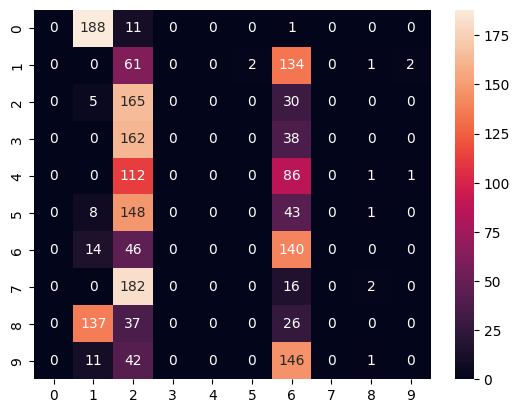

In [112]:
# Confusion matrix for m = 1.3
num_groups = u6_crisp_2.shape[1]
clusters6_2 = np.zeros((num_groups, num_groups))
rows = u6_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters6_2[h] = np.sum(u6_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters6_2 = pd.DataFrame(clusters6_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters6_2, annot=True, fmt="d")

In [113]:
clusters6_2

,0,1,2,3,4,5,6,7,8,9
0,0,188,11,0,0,0,1,0,0,0
1,0,0,61,0,0,2,134,0,1,2
2,0,5,165,0,0,0,30,0,0,0
3,0,0,162,0,0,0,38,0,0,0
4,0,0,112,0,0,0,86,0,1,1
5,0,8,148,0,0,0,43,0,1,0
6,0,14,46,0,0,0,140,0,0,0
7,0,0,182,0,0,0,16,0,2,0
8,0,137,37,0,0,0,26,0,0,0
9,0,11,42,0,0,0,146,0,1,0


In [114]:
np.savetxt("metrics_6_2_s.csv", model_arrays_6_2[best_index_6_2]["s"], delimiter=",")
np.savetxt("metrics_6_2_G.csv", model_arrays_6_2[best_index_6_2]["G"], delimiter=",")

## <a id='toc3_5_'></a>[m = 1.7](#toc0_)

### <a id='toc3_5_1_'></a>[Dataset 0](#toc0_)

In [ ]:
n_clusters = 10
m = 1.7
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays_7 = []
metrics_7 = []
best_loss = np.inf
best_index_7 = None
for i in range(n_runs):
    print("="*70)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_7 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_7.fit(Xs[0], ys[0])
    metrics_7.append(kfcm_7.evaluate())
    model_arrays_7.append({
        "U": kfcm_7._U,
        "G": kfcm_7._G,
        "s": kfcm_7._s,
    })
    if metrics_7[i]["loss"] < best_loss:
        best_loss = metrics_7[i]["loss"]
        best_index_7 = i

-> Run 1/50
Iteration 1: J = 778.0109981788322
{'accuracy': 0.5895, 'MPC': 0.0059899513777585955, 'rand': 0.4622111708085632, 'loss': 778.0109981788322}
Iteration 2: J = 772.7107691448273
{'accuracy': 0.586, 'MPC': 0.00549030196233502, 'rand': 0.4573601329211525, 'loss': 772.7107691448273}
Iteration 3: J = 767.339614308547
{'accuracy': 0.5905, 'MPC': 0.006188792259252285, 'rand': 0.46427332522630865, 'loss': 767.339614308547}
Iteration 4: J = 764.7354347776557
{'accuracy': 0.5925, 'MPC': 0.006945450861275737, 'rand': 0.45664836578835294, 'loss': 764.7354347776557}
Iteration 5: J = 763.2859903010226
{'accuracy': 0.5955, 'MPC': 0.007637709126919745, 'rand': 0.45018307422308995, 'loss': 763.2859903010226}
Iteration 6: J = 762.2616930918491
{'accuracy': 0.5965, 'MPC': 0.008276900072067161, 'rand': 0.4353947536221862, 'loss': 762.2616930918491}
Iteration 7: J = 761.512961663457
{'accuracy': 0.5935, 'MPC': 0.00867096508795373, 'rand': 0.4148517444539536, 'loss': 761.512961663457}
Iteration 8

In [ ]:
best_index_7, metrics_7[best_index_7]

(31,
 {'accuracy': 0.4455,
  'MPC': 0.00683737460494549,
  'rand': 0.266682982625772,
  'loss': 738.2757303593071})

In [ ]:
# Metrics for m = 1.3
acc_vec7 = [metrics_7[i]["accuracy"] for i in range(n_runs)]
rand_vec7 = [metrics_7[i]["rand"] for i in range(n_runs)]
mpc_vec7 = [metrics_7[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec7):.7f}" + u" \u00b1 " + f"{np.std(acc_vec7):.7f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec7):.7f}" + u" \u00b1 " + f"{np.std(rand_vec7):.7f}")
print(f"Mean MPC: {np.mean(mpc_vec7):.7f}" + u" \u00b1 " + f"{np.std(mpc_vec7):.7f}")

Mean Accuracy: 0.5732800 ± 0.0661586
Mean Adjusted Rand Score: 0.3857504 ± 0.0707196
Mean MPC: 0.0096940 ± 0.0013142


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u7 = pd.DataFrame(u3[best_j3])
#RODA DE NOVO
best_u7 = np.array(model_arrays_7[best_index_7]["U"])
u7_crisp = np.zeros_like(best_u7)
for k in range(best_u7.shape[0]):
    max_index = np.argmax(best_u7[k])
    u7_crisp[k][max_index] = 1

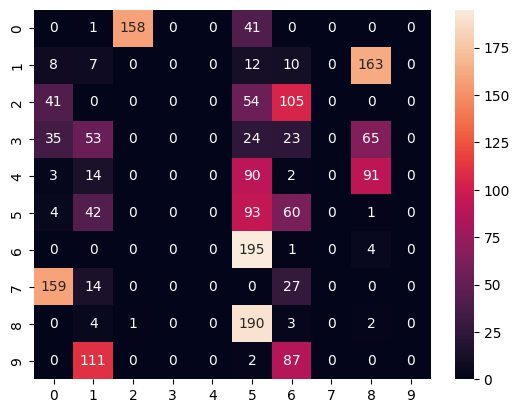

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u7_crisp.shape[1]
clusters7 = np.zeros((num_groups, num_groups))
rows = u7_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters7[h] = np.sum(u7_crisp[h*rows:(h+1)*rows], axis=0)
clusters7 = pd.DataFrame(clusters7.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters7, annot=True, fmt="d")

In [ ]:
clusters7

,0,1,2,3,4,5,6,7,8,9
0,0,1,158,0,0,41,0,0,0,0
1,8,7,0,0,0,12,10,0,163,0
2,41,0,0,0,0,54,105,0,0,0
3,35,53,0,0,0,24,23,0,65,0
4,3,14,0,0,0,90,2,0,91,0
5,4,42,0,0,0,93,60,0,1,0
6,0,0,0,0,0,195,1,0,4,0
7,159,14,0,0,0,0,27,0,0,0
8,0,4,1,0,0,190,3,0,2,0
9,0,111,0,0,0,2,87,0,0,0


In [ ]:
np.savetxt("metrics_7_s.csv", model_arrays_7[best_index_7]["s"], delimiter=",")
np.savetxt("metrics_7_G.csv", model_arrays_7[best_index_7]["G"], delimiter=",")

### <a id='toc3_5_2_'></a>[Dataset 1](#toc0_)

In [ ]:
n_clusters = 10
m = 1.7
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_7_1 = []
metrics_7_1 = []
best_loss = np.inf
best_index_7_1 = None
for i in range(n_runs):
    print("="*70)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_7_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_7_1.fit(Xs[1], ys[1])
    metrics_7_1.append(kfcm_7_1.evaluate())
    model_arrays_7_1.append({
        "U": kfcm_7_1._U,
        "G": kfcm_7_1._G,
        "s": kfcm_7_1._s,
    })
    if metrics_7_1[i]["loss"] < best_loss:
        best_loss = metrics_7_1[i]["loss"]
        best_index_7_1 = i

-> Run 1/50
Iteration 1: J = 555.0850366234065
{'accuracy': 0.4225, 'MPC': 0.006734143258652736, 'rand': 0.24219398991695565, 'loss': 555.0850366234065}
Iteration 2: J = 525.1951648112673
{'accuracy': 0.42, 'MPC': 0.0027826668889170403, 'rand': 0.28239276519909995, 'loss': 525.1951648112673}
Iteration 3: J = 520.9689420808018
{'accuracy': 0.364, 'MPC': 0.001507806988480409, 'rand': 0.23385684529017833, 'loss': 520.9689420808018}
Iteration 4: J = 519.9021254596373
{'accuracy': 0.319, 'MPC': 0.0009011864990626783, 'rand': 0.18948514118596235, 'loss': 519.9021254596373}
Iteration 5: J = 519.4051351009236
{'accuracy': 0.2835, 'MPC': 0.000546953510187409, 'rand': 0.17284141516174276, 'loss': 519.4051351009236}
Iteration 6: J = 519.1222466808335
{'accuracy': 0.2675, 'MPC': 0.00032535196336014316, 'rand': 0.15399168488659953, 'loss': 519.1222466808335}
Iteration 7: J = 518.9479155249254
{'accuracy': 0.2555, 'MPC': 0.00018653537127977238, 'rand': 0.13993811155144478, 'loss': 518.9479155249254}

In [ ]:
best_index_7_1, metrics_7_1[best_index_7_1]

(18,
 {'accuracy': 0.199,
  'MPC': 2.1748336465066131e-10,
  'rand': 0.10930969128984641,
  'loss': 518.6795335421617})

In [ ]:
# Metrics for m = 1.3
acc_vec7_1 = [metrics_7_1[i]["accuracy"] for i in range(n_runs)]
rand_vec7_1 = [metrics_7_1[i]["rand"] for i in range(n_runs)]
mpc_vec7_1 = [metrics_7_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec7_1):.7f}" + u" \u00b1 " + f"{np.std(acc_vec7_1):.7f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec7_1):.7f}" + u" \u00b1 " + f"{np.std(rand_vec7_1):.7f}")
print(f"Mean MPC: {np.mean(mpc_vec7_1):.7f}" + u" \u00b1 " + f"{np.std(mpc_vec7_1):.7f}")

Mean Accuracy: 0.1990000 ± 0.0000000
Mean Adjusted Rand Score: 0.1093097 ± 0.0000000
Mean MPC: 0.0000000 ± 0.0000000


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNVB
best_u7_1 = np.array(model_arrays_7_1[best_index_7_1]["U"])
u7_crisp_1 = np.zeros_like(best_u7_1)
for k in range(best_u7_1.shape[0]):
    max_index = np.argmax(best_u7_1[k])
    u7_crisp_1[k][max_index] = 1

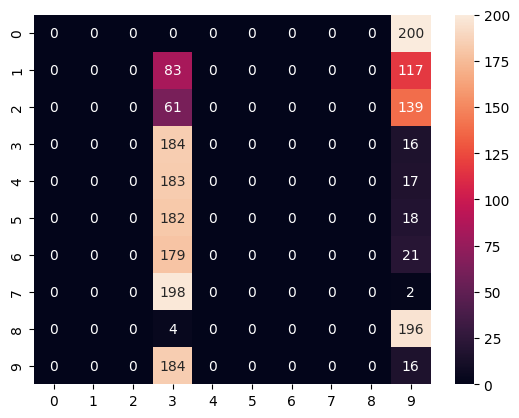

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u7_crisp_1.shape[1]
clusters7_1 = np.zeros((num_groups, num_groups))
rows = u7_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters7_1[h] = np.sum(u7_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters7_1 = pd.DataFrame(clusters7_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters7_1, annot=True, fmt="d")

In [ ]:
clusters7_1

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,0,0,0,0,0,0,200
1,0,0,0,83,0,0,0,0,0,117
2,0,0,0,61,0,0,0,0,0,139
3,0,0,0,184,0,0,0,0,0,16
4,0,0,0,183,0,0,0,0,0,17
5,0,0,0,182,0,0,0,0,0,18
6,0,0,0,179,0,0,0,0,0,21
7,0,0,0,198,0,0,0,0,0,2
8,0,0,0,4,0,0,0,0,0,196
9,0,0,0,184,0,0,0,0,0,16


In [ ]:

np.savetxt("metrics_7_1_s.csv", model_arrays_7_1[best_index_7_1]["s"], delimiter=",")
np.savetxt("metrics_7_1_G.csv", model_arrays_7_1[best_index_7_1]["G"], delimiter=",")

### <a id='toc3_5_3_'></a>[Dataset 2](#toc0_)

In [ ]:
n_clusters = 10
m = 1.7
max_iter = 100
tol = 1e-6

n_runs = 50

model_arrays_7_2 = []
metrics_7_2 = []
best_loss = np.inf
best_index_7_2 = None
for i in range(n_runs):
    print("="*70)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_7_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_7_2.fit(Xs[2], ys[2])
    metrics_7_2.append(kfcm_7_2.evaluate())
    model_arrays_7_2.append({
        "U": kfcm_7_2._U,
        "G": kfcm_7_2._G,
        "s": kfcm_7_2._s,
    })
    if metrics_7_2[i]["loss"] < best_loss:
        best_loss = metrics_7_2[i]["loss"]
        best_index_7_2 = i

-> Run 1/50
Iteration 1: J = 395.4635306737426
{'accuracy': 0.503, 'MPC': 0.024570769891022914, 'rand': 0.3004083986999956, 'loss': 395.4635306737426}
Iteration 2: J = 383.5236603832135
{'accuracy': 0.4745, 'MPC': 0.01904947240257504, 'rand': 0.27936413685451517, 'loss': 383.5236603832135}
Iteration 3: J = 381.1709871827999
{'accuracy': 0.4395, 'MPC': 0.016363603583764763, 'rand': 0.252271365096324, 'loss': 381.1709871827999}
Iteration 4: J = 380.4048445102144
{'accuracy': 0.427, 'MPC': 0.014813581526697539, 'rand': 0.24682496127826875, 'loss': 380.4048445102144}
Iteration 5: J = 380.0217758248305
{'accuracy': 0.409, 'MPC': 0.013828690587238124, 'rand': 0.23763471887450627, 'loss': 380.0217758248305}
Iteration 6: J = 379.7753628375058
{'accuracy': 0.3945, 'MPC': 0.013169327756318738, 'rand': 0.23149969968465514, 'loss': 379.7753628375058}
Iteration 7: J = 379.5955550354092
{'accuracy': 0.3835, 'MPC': 0.012714412615349335, 'rand': 0.22298076628600816, 'loss': 379.5955550354092}
Iteratio

In [ ]:
best_index_7_2, metrics_7_2[best_index_7_2]

(34,
 {'accuracy': 0.26,
  'MPC': 0.011382364073915019,
  'rand': 0.12721268157324742,
  'loss': 378.9626654448191})

In [ ]:
# Metrics for m = 1.3
acc_vec7_2 = [metrics_7_2[i]["accuracy"] for i in range(n_runs)]
rand_vec7_2 = [metrics_7_2[i]["rand"] for i in range(n_runs)]
mpc_vec7_2 = [metrics_7_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec7_2):.7f}" + u" \u00b1 " + f"{np.std(acc_vec7_2):.7f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec7_2):.7f}" + u" \u00b1 " + f"{np.std(rand_vec7_2):.7f}")
print(f"Mean MPC: {np.mean(mpc_vec7_2):.7f}" + u" \u00b1 " + f"{np.std(mpc_vec7_2):.7f}")

Mean Accuracy: 0.2630900 ± 0.0035745
Mean Adjusted Rand Score: 0.1295847 ± 0.0025128
Mean MPC: 0.0113862 ± 0.0000006


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u7_2 = np.array(model_arrays_7_2[best_index_7_2]["U"])
u7_crisp_2 = np.zeros_like(best_u7_2)
for k in range(best_u7_2.shape[0]):
    max_index = np.argmax(best_u7_2[k])
    u7_crisp_2[k][max_index] = 1

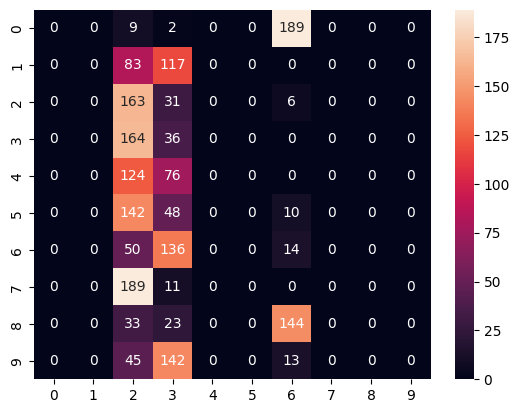

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u7_crisp_2.shape[1]
clusters7_2 = np.zeros((num_groups, num_groups))
rows = u7_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters7_2[h] = np.sum(u7_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters7_2 = pd.DataFrame(clusters7_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters7_2, annot=True, fmt="d")

In [ ]:
clusters7_2

,0,1,2,3,4,5,6,7,8,9
0,0,0,9,2,0,0,189,0,0,0
1,0,0,83,117,0,0,0,0,0,0
2,0,0,163,31,0,0,6,0,0,0
3,0,0,164,36,0,0,0,0,0,0
4,0,0,124,76,0,0,0,0,0,0
5,0,0,142,48,0,0,10,0,0,0
6,0,0,50,136,0,0,14,0,0,0
7,0,0,189,11,0,0,0,0,0,0
8,0,0,33,23,0,0,144,0,0,0
9,0,0,45,142,0,0,13,0,0,0


In [ ]:

np.savetxt("metrics_7_2_s.csv", model_arrays_7_2[best_index_7_2]["s"], delimiter=",")
np.savetxt("metrics_7_2_G.csv", model_arrays_7_2[best_index_7_2]["G"], delimiter=",")

## <a id='toc3_6_'></a>[m = 1.8](#toc0_)

### <a id='toc3_6_1_'></a>[Dataset 0](#toc0_)

In [ ]:
n_clusters = 10
m = 1.8
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays_8 = []
metrics_8 = []
best_loss = np.inf
best_index_8 = None
for i in range(n_runs):
    print("="*80)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_8 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_8.fit(Xs[0], ys[0])
    metrics_8.append(kfcm_8.evaluate())
    model_arrays_8.append({
        "U": kfcm_8._U,
        "G": kfcm_8._G,
        "s": kfcm_8._s,
    })
    if metrics_8[i]["loss"] < best_loss:
        best_loss = metrics_8[i]["loss"]
        best_index_8 = i

-> Run 1/50
Iteration 1: J = 611.956648979782
{'accuracy': 0.5695, 'MPC': 0.006347465529645824, 'rand': 0.39114906194814025, 'loss': 611.956648979782}
Iteration 2: J = 608.3584993749066
{'accuracy': 0.601, 'MPC': 0.005378328533816812, 'rand': 0.4104015638556848, 'loss': 608.3584993749066}
Iteration 3: J = 604.3352623465385
{'accuracy': 0.652, 'MPC': 0.005411159261173748, 'rand': 0.4642956861509855, 'loss': 604.3352623465385}
Iteration 4: J = 601.4600242595266
{'accuracy': 0.676, 'MPC': 0.005878034955131617, 'rand': 0.49035855479077833, 'loss': 601.4600242595266}
Iteration 5: J = 599.9557192312886
{'accuracy': 0.689, 'MPC': 0.0061859996250779314, 'rand': 0.4972479458720071, 'loss': 599.9557192312886}
Iteration 6: J = 598.9999953569575
{'accuracy': 0.6915, 'MPC': 0.006338725964038838, 'rand': 0.4909493506719805, 'loss': 598.9999953569575}
Iteration 7: J = 598.3124523214767
{'accuracy': 0.687, 'MPC': 0.006420189216485017, 'rand': 0.4834627276876081, 'loss': 598.3124523214767}
Iteration 8:

In [ ]:
best_index_8, metrics_8[best_index_8]

(31,
 {'accuracy': 0.4475,
  'MPC': 0.004857137599120986,
  'rand': 0.2673783336514284,
  'loss': 587.4040464545959})

In [ ]:
# Metrics for m = 1.3
acc_vec8 = [metrics_8[i]["accuracy"] for i in range(n_runs)]
rand_vec8 = [metrics_8[i]["rand"] for i in range(n_runs)]
mpc_vec8 = [metrics_8[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec8):.8f}" + u" \u00b1 " + f"{np.std(acc_vec8):.8f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec8):.8f}" + u" \u00b1 " + f"{np.std(rand_vec8):.8f}")
print(f"Mean MPC: {np.mean(mpc_vec8):.8f}" + u" \u00b1 " + f"{np.std(mpc_vec8):.8f}")

Mean Accuracy: 0.56566000 ± 0.06733012
Mean Adjusted Rand Score: 0.37576652 ± 0.07442023
Mean MPC: 0.00686754 ± 0.00086385


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u8 = pd.DataFrame(u3[best_j3])
#RODA DE NOVO
best_u8 = np.array(model_arrays_8[best_index_8]["U"])
u8_crisp = np.zeros_like(best_u8)
for k in range(best_u8.shape[0]):
    max_index = np.argmax(best_u8[k])
    u8_crisp[k][max_index] = 1

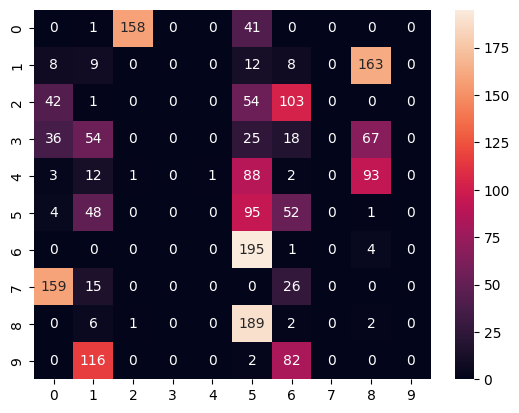

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u8_crisp.shape[1]
clusters8 = np.zeros((num_groups, num_groups))
rows = u8_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters8[h] = np.sum(u8_crisp[h*rows:(h+1)*rows], axis=0)
clusters8 = pd.DataFrame(clusters8.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters8, annot=True, fmt="d")

In [ ]:
clusters8

,0,1,2,3,4,5,6,7,8,9
0,0,1,158,0,0,41,0,0,0,0
1,8,9,0,0,0,12,8,0,163,0
2,42,1,0,0,0,54,103,0,0,0
3,36,54,0,0,0,25,18,0,67,0
4,3,12,1,0,1,88,2,0,93,0
5,4,48,0,0,0,95,52,0,1,0
6,0,0,0,0,0,195,1,0,4,0
7,159,15,0,0,0,0,26,0,0,0
8,0,6,1,0,0,189,2,0,2,0
9,0,116,0,0,0,2,82,0,0,0


In [ ]:
np.savetxt("metrics_8_s.csv", model_arrays_8[best_index_8]["s"], delimiter=",")
np.savetxt("metrics_8_G.csv", model_arrays_8[best_index_8]["G"], delimiter=",")

### <a id='toc3_6_2_'></a>[Dataset 1](#toc0_)

In [ ]:
n_clusters = 10
m = 1.8
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_8_1 = []
metrics_8_1 = []
best_loss = np.inf
best_index_8_1 = None
for i in range(n_runs):
    print("="*80)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_8_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_8_1.fit(Xs[1], ys[1])
    metrics_8_1.append(kfcm_8_1.evaluate())
    model_arrays_8_1.append({
        "U": kfcm_8_1._U,
        "G": kfcm_8_1._G,
        "s": kfcm_8_1._s,
    })
    if metrics_8_1[i]["loss"] < best_loss:
        best_loss = metrics_8_1[i]["loss"]
        best_index_8_1 = i

-> Run 1/50
Iteration 1: J = 444.16450516350005
{'accuracy': 0.414, 'MPC': 0.005161745851183452, 'rand': 0.2400291090514088, 'loss': 444.16450516350005}
Iteration 2: J = 417.877847297424
{'accuracy': 0.4185, 'MPC': 0.001967696952809961, 'rand': 0.28347640793762746, 'loss': 417.877847297424}
Iteration 3: J = 413.78041184203437
{'accuracy': 0.361, 'MPC': 0.0009412852954695516, 'rand': 0.23073247982270348, 'loss': 413.78041184203437}
Iteration 4: J = 412.84327261194653
{'accuracy': 0.3115, 'MPC': 0.0005007015088202005, 'rand': 0.1851799681674282, 'loss': 412.84327261194653}
Iteration 5: J = 412.44822181960683
{'accuracy': 0.2745, 'MPC': 0.00026619656266468894, 'rand': 0.16570731992540166, 'loss': 412.44822181960683}
Iteration 6: J = 412.24116260393566
{'accuracy': 0.256, 'MPC': 0.00013672805422670908, 'rand': 0.14293306010788775, 'loss': 412.24116260393566}
Iteration 7: J = 412.1264373197582
{'accuracy': 0.244, 'MPC': 6.737131512168926e-05, 'rand': 0.1313778152219131, 'loss': 412.12643731

In [ ]:
best_index_8_1, metrics_8_1[best_index_8_1]

(19,
 {'accuracy': 0.199,
  'MPC': 1.493989376655236e-10,
  'rand': 0.10930969128984641,
  'loss': 412.00179826004177})

In [ ]:
# Metrics for m = 1.3
acc_vec8_1 = [metrics_8_1[i]["accuracy"] for i in range(n_runs)]
rand_vec8_1 = [metrics_8_1[i]["rand"] for i in range(n_runs)]
mpc_vec8_1 = [metrics_8_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec8_1):.8f}" + u" \u00b1 " + f"{np.std(acc_vec8_1):.8f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec8_1):.8f}" + u" \u00b1 " + f"{np.std(rand_vec8_1):.8f}")
print(f"Mean MPC: {np.mean(mpc_vec8_1):.8f}" + u" \u00b1 " + f"{np.std(mpc_vec8_1):.8f}")

Mean Accuracy: 0.19900000 ± 0.00000000
Mean Adjusted Rand Score: 0.10930969 ± 0.00000000
Mean MPC: 0.00000000 ± 0.00000000


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNVB
best_u8_1 = np.array(model_arrays_8_1[best_index_8_1]["U"])
u8_crisp_1 = np.zeros_like(best_u8_1)
for k in range(best_u8_1.shape[0]):
    max_index = np.argmax(best_u8_1[k])
    u8_crisp_1[k][max_index] = 1

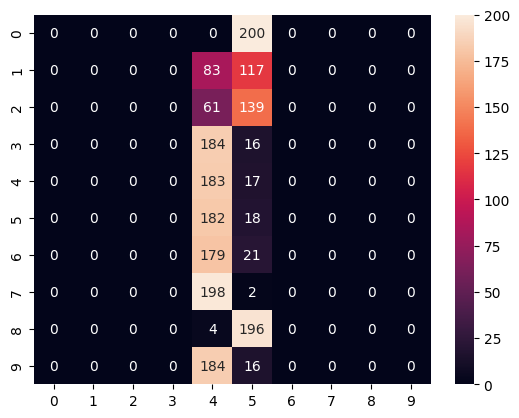

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u8_crisp_1.shape[1]
clusters8_1 = np.zeros((num_groups, num_groups))
rows = u8_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters8_1[h] = np.sum(u8_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters8_1 = pd.DataFrame(clusters8_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters8_1, annot=True, fmt="d")

In [ ]:
clusters8_1

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,0,0,200,0,0,0,0
1,0,0,0,0,83,117,0,0,0,0
2,0,0,0,0,61,139,0,0,0,0
3,0,0,0,0,184,16,0,0,0,0
4,0,0,0,0,183,17,0,0,0,0
5,0,0,0,0,182,18,0,0,0,0
6,0,0,0,0,179,21,0,0,0,0
7,0,0,0,0,198,2,0,0,0,0
8,0,0,0,0,4,196,0,0,0,0
9,0,0,0,0,184,16,0,0,0,0


In [ ]:

np.savetxt("metrics_8_1_s.csv", model_arrays_8_1[best_index_8_1]["s"], delimiter=",")
np.savetxt("metrics_8_1_G.csv", model_arrays_8_1[best_index_8_1]["G"], delimiter=",")

### <a id='toc3_6_3_'></a>[Dataset 2](#toc0_)

In [ ]:
n_clusters = 10
m = 1.8
max_iter = 100
tol = 1e-6

n_runs = 50

model_arrays_8_2 = []
metrics_8_2 = []
best_loss = np.inf
best_index_8_2 = None
for i in range(n_runs):
    print("="*80)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_8_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_8_2.fit(Xs[2], ys[2])
    metrics_8_2.append(kfcm_8_2.evaluate())
    model_arrays_8_2.append({
        "U": kfcm_8_2._U,
        "G": kfcm_8_2._G,
        "s": kfcm_8_2._s,
    })
    if metrics_8_2[i]["loss"] < best_loss:
        best_loss = metrics_8_2[i]["loss"]
        best_index_8_2 = i

-> Run 1/50
Iteration 1: J = 315.9495467926813
{'accuracy': 0.4995, 'MPC': 0.017526290530057387, 'rand': 0.2969257656482299, 'loss': 315.9495467926813}
Iteration 2: J = 305.5512263788638
{'accuracy': 0.4665, 'MPC': 0.012818462526494767, 'rand': 0.27129341867685913, 'loss': 305.5512263788638}
Iteration 3: J = 303.5440657733012
{'accuracy': 0.4305, 'MPC': 0.010482974913385457, 'rand': 0.2466053881736898, 'loss': 303.5440657733012}
Iteration 4: J = 302.86973214212423
{'accuracy': 0.411, 'MPC': 0.009109696955758584, 'rand': 0.2402683468055783, 'loss': 302.86973214212423}
Iteration 5: J = 302.52012359944285
{'accuracy': 0.3915, 'MPC': 0.008230921562413895, 'rand': 0.23387507508796565, 'loss': 302.52012359944285}
Iteration 6: J = 302.29672280441997
{'accuracy': 0.376, 'MPC': 0.0076452041223595835, 'rand': 0.22515431981065542, 'loss': 302.29672280441997}
Iteration 7: J = 302.14111555805584
{'accuracy': 0.3625, 'MPC': 0.007247237092410819, 'rand': 0.21741438938309618, 'loss': 302.1411155580558

In [ ]:
best_index_8_2, metrics_8_2[best_index_8_2]

(30,
 {'accuracy': 0.2635,
  'MPC': 0.0063110874792646765,
  'rand': 0.12657816534652402,
  'loss': 301.74687081555527})

In [ ]:
# Metrics for m = 1.3
acc_vec8_2 = [metrics_8_2[i]["accuracy"] for i in range(n_runs)]
rand_vec8_2 = [metrics_8_2[i]["rand"] for i in range(n_runs)]
mpc_vec8_2 = [metrics_8_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec8_2):.8f}" + u" \u00b1 " + f"{np.std(acc_vec8_2):.8f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec8_2):.8f}" + u" \u00b1 " + f"{np.std(rand_vec8_2):.8f}")
print(f"Mean MPC: {np.mean(mpc_vec8_2):.8f}" + u" \u00b1 " + f"{np.std(mpc_vec8_2):.8f}")

Mean Accuracy: 0.25635000 ± 0.02252449
Mean Adjusted Rand Score: 0.12273557 ± 0.01180591
Mean MPC: 0.00554993 ± 0.00204944


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u8_2 = np.array(model_arrays_8_2[best_index_8_2]["U"])
u8_crisp_2 = np.zeros_like(best_u8_2)
for k in range(best_u8_2.shape[0]):
    max_index = np.argmax(best_u8_2[k])
    u8_crisp_2[k][max_index] = 1

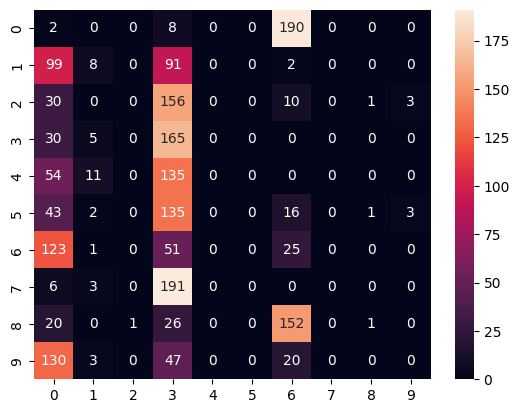

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u8_crisp_2.shape[1]
clusters8_2 = np.zeros((num_groups, num_groups))
rows = u8_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters8_2[h] = np.sum(u8_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters8_2 = pd.DataFrame(clusters8_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters8_2, annot=True, fmt="d")

In [ ]:
clusters8_2

,0,1,2,3,4,5,6,7,8,9
0,2,0,0,8,0,0,190,0,0,0
1,99,8,0,91,0,0,2,0,0,0
2,30,0,0,156,0,0,10,0,1,3
3,30,5,0,165,0,0,0,0,0,0
4,54,11,0,135,0,0,0,0,0,0
5,43,2,0,135,0,0,16,0,1,3
6,123,1,0,51,0,0,25,0,0,0
7,6,3,0,191,0,0,0,0,0,0
8,20,0,1,26,0,0,152,0,1,0
9,130,3,0,47,0,0,20,0,0,0


In [ ]:
np.savetxt("metrics_8_2_s.csv", model_arrays_8_2[best_index_8_2]["s"], delimiter=",")
np.savetxt("metrics_8_2_G.csv", model_arrays_8_2[best_index_8_2]["G"], delimiter=",")

## <a id='toc3_7_'></a>[m = 1.9](#toc0_)

### <a id='toc3_7_1_'></a>[Dataset 0](#toc0_)

In [ ]:
n_clusters = 10
m = 1.9
max_iter = 100
tol = 1e-6
n_runs = 50

model_arrays_9 = []
metrics_9 = []
best_loss = np.inf
best_index_9 = None
for i in range(n_runs):
    print("="*90)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_9 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    kfcm_9.fit(Xs[0], ys[0])
    metrics_9.append(kfcm_9.evaluate())
    model_arrays_9.append({
        "U": kfcm_9._U,
        "G": kfcm_9._G,
        "s": kfcm_9._s,
    })
    if metrics_9[i]["loss"] < best_loss:
        best_loss = metrics_9[i]["loss"]
        best_index_9 = i

-> Run 1/50
Iteration 1: J = 486.9996524335331
{'accuracy': 0.571, 'MPC': 0.005212751239002111, 'rand': 0.39263023850927964, 'loss': 486.9996524335331}
Iteration 2: J = 484.4058705196866
{'accuracy': 0.587, 'MPC': 0.004123513283751046, 'rand': 0.40213143946089736, 'loss': 484.4058705196866}
Iteration 3: J = 481.2612734418501
{'accuracy': 0.6455, 'MPC': 0.003925554327813052, 'rand': 0.4563070265408191, 'loss': 481.2612734418501}
Iteration 4: J = 478.8379787981409
{'accuracy': 0.6735, 'MPC': 0.0041933960870688125, 'rand': 0.4884829648535739, 'loss': 478.8379787981409}
Iteration 5: J = 477.49201025973
{'accuracy': 0.6835, 'MPC': 0.004435990651521782, 'rand': 0.4925644842996447, 'loss': 477.49201025973}
Iteration 6: J = 476.7007117422693
{'accuracy': 0.6855, 'MPC': 0.0045432980501941556, 'rand': 0.4857034310946881, 'loss': 476.7007117422693}
Iteration 7: J = 476.0719718091647
{'accuracy': 0.681, 'MPC': 0.004588387841728436, 'rand': 0.4756798776796915, 'loss': 476.0719718091647}
Iteration 8

In [ ]:
best_index_9, metrics_9[best_index_9]

(31,
 {'accuracy': 0.451,
  'MPC': 0.0036869652547164566,
  'rand': 0.26898399411975843,
  'loss': 467.1600031353004})

In [ ]:
# Metrics for m = 1.3
acc_vec9 = [metrics_9[i]["accuracy"] for i in range(n_runs)]
rand_vec9 = [metrics_9[i]["rand"] for i in range(n_runs)]
mpc_vec9 = [metrics_9[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec9):.9f}" + u" \u00b1 " + f"{np.std(acc_vec9):.9f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec9):.9f}" + u" \u00b1 " + f"{np.std(rand_vec9):.9f}")
print(f"Mean MPC: {np.mean(mpc_vec9):.9f}" + u" \u00b1 " + f"{np.std(mpc_vec9):.9f}")

Mean Accuracy: 0.554040000 ± 0.070687258
Mean Adjusted Rand Score: 0.367846477 ± 0.076592881
Mean MPC: 0.005105585 ± 0.000616507


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u9 = pd.DataFrame(u3[best_j3])
#RODA DE NOVO
best_u9 = np.array(model_arrays_9[best_index_9]["U"])
u9_crisp = np.zeros_like(best_u9)
for k in range(best_u9.shape[0]):
    max_index = np.argmax(best_u9[k])
    u9_crisp[k][max_index] = 1

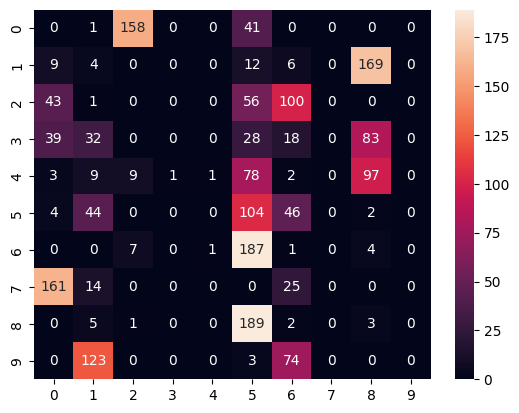

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u9_crisp.shape[1]
clusters9 = np.zeros((num_groups, num_groups))
rows = u9_crisp.shape[0] // num_groups
for h in range(num_groups):
    clusters9[h] = np.sum(u9_crisp[h*rows:(h+1)*rows], axis=0)
clusters9 = pd.DataFrame(clusters9.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters9, annot=True, fmt="d")

In [ ]:
clusters9

,0,1,2,3,4,5,6,7,8,9
0,0,1,158,0,0,41,0,0,0,0
1,9,4,0,0,0,12,6,0,169,0
2,43,1,0,0,0,56,100,0,0,0
3,39,32,0,0,0,28,18,0,83,0
4,3,9,9,1,1,78,2,0,97,0
5,4,44,0,0,0,104,46,0,2,0
6,0,0,7,0,1,187,1,0,4,0
7,161,14,0,0,0,0,25,0,0,0
8,0,5,1,0,0,189,2,0,3,0
9,0,123,0,0,0,3,74,0,0,0


In [ ]:
np.savetxt("metrics_9_s.csv", model_arrays_9[best_index_9]["s"], delimiter=",")
np.savetxt("metrics_9_G.csv", model_arrays_9[best_index_9]["G"], delimiter=",")

### <a id='toc3_7_2_'></a>[Dataset 1](#toc0_)

In [ ]:
n_clusters = 10
m = 1.9
max_iter = 100
tol = 1e-6
random_state = 42

n_runs = 50

model_arrays_9_1 = []
metrics_9_1 = []
best_loss = np.inf
best_index_9_1 = None
for i in range(n_runs):
    print("="*90)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_9_1 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 1
    kfcm_9_1.fit(Xs[1], ys[1])
    metrics_9_1.append(kfcm_9_1.evaluate())
    model_arrays_9_1.append({
        "U": kfcm_9_1._U,
        "G": kfcm_9_1._G,
        "s": kfcm_9_1._s,
    })
    if metrics_9_1[i]["loss"] < best_loss:
        best_loss = metrics_9_1[i]["loss"]
        best_index_9_1 = i

-> Run 1/50
Iteration 1: J = 355.74127015947045
{'accuracy': 0.4115, 'MPC': 0.004157055211769567, 'rand': 0.23820576828308188, 'loss': 355.74127015947045}
Iteration 2: J = 332.8030680175044
{'accuracy': 0.4195, 'MPC': 0.00153666716949441, 'rand': 0.28157737205435696, 'loss': 332.8030680175044}
Iteration 3: J = 328.6846259336754
{'accuracy': 0.3595, 'MPC': 0.0006457120190783705, 'rand': 0.22914338143716456, 'loss': 328.6846259336754}
Iteration 4: J = 327.86045074461344
{'accuracy': 0.3025, 'MPC': 0.00030936618886967526, 'rand': 0.18041954694898893, 'loss': 327.86045074461344}
Iteration 5: J = 327.5496635908753
{'accuracy': 0.266, 'MPC': 0.0001472170971971165, 'rand': 0.1576576668341184, 'loss': 327.5496635908753}
Iteration 6: J = 327.4011130733408
{'accuracy': 0.253, 'MPC': 6.748921779609063e-05, 'rand': 0.13710951605886879, 'loss': 327.4011130733408}
Iteration 7: J = 327.3277032929466
{'accuracy': 0.2365, 'MPC': 2.9789944674063484e-05, 'rand': 0.12720093086008763, 'loss': 327.327703292

In [ ]:
best_index_9_1, metrics_9_1[best_index_9_1]

(17,
 {'accuracy': 0.1995,
  'MPC': 1.163730223296966e-10,
  'rand': 0.10929106113895624,
  'loss': 327.2646611287956})

In [ ]:
# Metrics for m = 1.3
acc_vec9_1 = [metrics_9_1[i]["accuracy"] for i in range(n_runs)]
rand_vec9_1 = [metrics_9_1[i]["rand"] for i in range(n_runs)]
mpc_vec9_1 = [metrics_9_1[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec9_1):.9f}" + u" \u00b1 " + f"{np.std(acc_vec9_1):.9f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec9_1):.9f}" + u" \u00b1 " + f"{np.std(rand_vec9_1):.9f}")
print(f"Mean MPC: {np.mean(mpc_vec9_1):.9f}" + u" \u00b1 " + f"{np.std(mpc_vec9_1):.9f}")

Mean Accuracy: 0.199010000 ± 0.000070000
Mean Adjusted Rand Score: 0.109309319 ± 0.000002608
Mean MPC: 0.000000000 ± 0.000000000


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
# RODA DNVB
best_u9_1 = np.array(model_arrays_9_1[best_index_9_1]["U"])
u9_crisp_1 = np.zeros_like(best_u9_1)
for k in range(best_u9_1.shape[0]):
    max_index = np.argmax(best_u9_1[k])
    u9_crisp_1[k][max_index] = 1

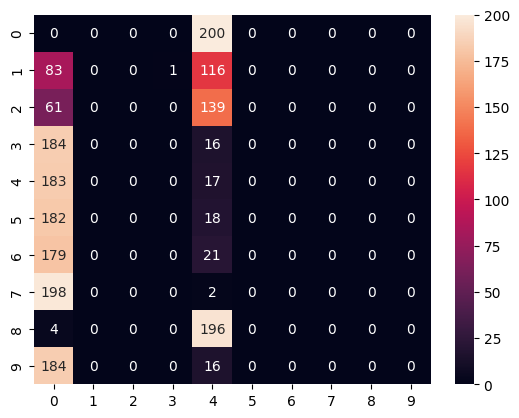

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u9_crisp_1.shape[1]
clusters9_1 = np.zeros((num_groups, num_groups))
rows = u9_crisp_1.shape[0] // num_groups
for h in range(num_groups):
    clusters9_1[h] = np.sum(u9_crisp_1[h*rows:(h+1)*rows], axis=0)
clusters9_1 = pd.DataFrame(clusters9_1.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters9_1, annot=True, fmt="d")

In [ ]:
clusters9_1

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,0,200,0,0,0,0,0
1,83,0,0,1,116,0,0,0,0,0
2,61,0,0,0,139,0,0,0,0,0
3,184,0,0,0,16,0,0,0,0,0
4,183,0,0,0,17,0,0,0,0,0
5,182,0,0,0,18,0,0,0,0,0
6,179,0,0,0,21,0,0,0,0,0
7,198,0,0,0,2,0,0,0,0,0
8,4,0,0,0,196,0,0,0,0,0
9,184,0,0,0,16,0,0,0,0,0


In [ ]:
np.savetxt("metrics_9_1_s.csv", model_arrays_9_1[best_index_9_1]["s"], delimiter=",")
np.savetxt("metrics_9_1_G.csv", model_arrays_9_1[best_index_9_1]["G"], delimiter=",")

### <a id='toc3_7_3_'></a>[Dataset 2](#toc0_)

In [ ]:
n_clusters = 10
m = 1.9
max_iter = 100
tol = 1e-6

n_runs = 50

model_arrays_9_2 = []
metrics_9_2 = []
best_loss = np.inf
best_index_9_2 = None
for i in range(n_runs):
    print("="*90)
    print(f"-> Run {i+1}/{n_runs}")
    kfcm_9_2 = KFCM_K_W1(n_clusters=n_clusters, m=m, n_iter=max_iter, epsilon=tol, verbose=True, random_state=i)
    # Dataset 2
    kfcm_9_2.fit(Xs[2], ys[2])
    metrics_9_2.append(kfcm_9_2.evaluate())
    model_arrays_9_2.append({
        "U": kfcm_9_2._U,
        "G": kfcm_9_2._G,
        "s": kfcm_9_2._s,
    })
    if metrics_9_2[i]["loss"] < best_loss:
        best_loss = metrics_9_2[i]["loss"]
        best_index_9_2 = i

-> Run 1/50
Iteration 1: J = 252.29932503838074
{'accuracy': 0.495, 'MPC': 0.013108941511921435, 'rand': 0.2915012522346486, 'loss': 252.29932503838074}
Iteration 2: J = 243.2226401365501
{'accuracy': 0.463, 'MPC': 0.009061252294451871, 'rand': 0.2677690106598336, 'loss': 243.2226401365501}
Iteration 3: J = 241.49274859217573
{'accuracy': 0.4265, 'MPC': 0.007038156605323254, 'rand': 0.2443922988594563, 'loss': 241.49274859217573}
Iteration 4: J = 240.89935775847488
{'accuracy': 0.4055, 'MPC': 0.005833432931385718, 'rand': 0.23928885009459538, 'loss': 240.89935775847488}
Iteration 5: J = 240.58974740148747
{'accuracy': 0.374, 'MPC': 0.005048119641007154, 'rand': 0.22607237267692465, 'loss': 240.58974740148747}
Iteration 6: J = 240.39777876008708
{'accuracy': 0.3605, 'MPC': 0.00450881756763577, 'rand': 0.216995361177414, 'loss': 240.39777876008708}
Iteration 7: J = 240.27115473688553
{'accuracy': 0.3455, 'MPC': 0.004124773302280227, 'rand': 0.20666337659198697, 'loss': 240.27115473688553

In [ ]:
best_index_9_2, metrics_9_2[best_index_9_2]

(15,
 {'accuracy': 0.1975,
  'MPC': 8.598077028132423e-09,
  'rand': 0.0925864398298979,
  'loss': 239.8281263076119})

In [ ]:
# Metrics for m = 1.3
acc_vec9_2 = [metrics_9_2[i]["accuracy"] for i in range(n_runs)]
rand_vec9_2 = [metrics_9_2[i]["rand"] for i in range(n_runs)]
mpc_vec9_2 = [metrics_9_2[i]["MPC"] for i in range(n_runs)]

print(f"Mean Accuracy: {np.mean(acc_vec9_2):.9f}" + u" \u00b1 " + f"{np.std(acc_vec9_2):.9f}")
print(f"Mean Adjusted Rand Score: {np.mean(rand_vec9_2):.9f}" + u" \u00b1 " + f"{np.std(rand_vec9_2):.9f}")
print(f"Mean MPC: {np.mean(mpc_vec9_2):.9f}" + u" \u00b1 " + f"{np.std(mpc_vec9_2):.9f}")

Mean Accuracy: 0.197640000 ± 0.000224499
Mean Adjusted Rand Score: 0.092512461 ± 0.000096526
Mean MPC: 0.000000063 ± 0.000000127


In [ ]:
# Crisp partition of the best result for m = 1.3
#best_u3 = pd.DataFrame(u3[best_j3])
best_u9_2 = np.array(model_arrays_9_2[best_index_9_2]["U"])
u9_crisp_2 = np.zeros_like(best_u9_2)
for k in range(best_u9_2.shape[0]):
    max_index = np.argmax(best_u9_2[k])
    u9_crisp_2[k][max_index] = 1

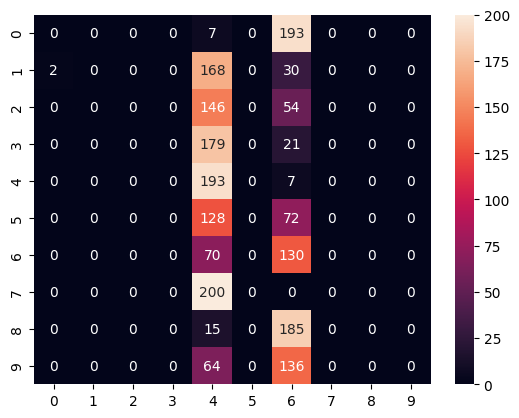

In [ ]:
# Confusion matrix for m = 1.3
num_groups = u9_crisp_2.shape[1]
clusters9_2 = np.zeros((num_groups, num_groups))
rows = u9_crisp_2.shape[0] // num_groups
for h in range(num_groups):
    clusters9_2[h] = np.sum(u9_crisp_2[h*rows:(h+1)*rows], axis=0)
clusters9_2 = pd.DataFrame(clusters9_2.astype(int))

with sns.plotting_context():
    sns.heatmap(clusters9_2, annot=True, fmt="d")

In [ ]:
clusters9_2

,0,1,2,3,4,5,6,7,8,9
0,0,0,0,0,7,0,193,0,0,0
1,2,0,0,0,168,0,30,0,0,0
2,0,0,0,0,146,0,54,0,0,0
3,0,0,0,0,179,0,21,0,0,0
4,0,0,0,0,193,0,7,0,0,0
5,0,0,0,0,128,0,72,0,0,0
6,0,0,0,0,70,0,130,0,0,0
7,0,0,0,0,200,0,0,0,0,0
8,0,0,0,0,15,0,185,0,0,0
9,0,0,0,0,64,0,136,0,0,0


In [ ]:
np.savetxt("metrics_9_2_s.csv", model_arrays_9_2[best_index_9_2]["s"], delimiter=",")
np.savetxt("metrics_9_2_G.csv", model_arrays_9_2[best_index_9_2]["G"], delimiter=",")